# Máquinas Térmicas - Lección 14a (Bonus)
## El turbohélice PT6A-61 completo: de la llama al empuje

**Fuentes estudiantiles:**
- Sofía V. Delgado Pinzón, Juan P. González Posada, Juan J. Reyes Perilla y C. A. Bayona Roa (PUJ, 2024) — *Simulation of Turboprop Systems using Simulink: Development and Validation of Computational Mechanical Model* (manuscrito, `research_sources/Turboprop Engine/main.tex`). Incluye los modelos Simulink del motor, el bloque de la hélice McCauley (método de Traub con coeficientes de XFOIL) y el control PID del paso.
- Diego A. Castellanos Proaños (dir. C. A. Bayona Roa; asesor A. G. Rodríguez Meléndez), Universidad ECCI, 2019 — *Simulación computacional de operación de turbina de gas tipo PT6* (tesis y modelo Simulink `PT6FINAL`, dentro de `PT6 Simulation.zip`).

**Datos reales de validación:**
- Pratt & Whitney Canada, **carta de estaciones** presión-temperatura del PT6A en despegue, día estándar, nivel del mar (reproducida en la tesis de 2019, digitalizada aquí).
- EASA, **TCDS IM.E.078** (PT6A-41 series, 2022): potencia de despegue del PT6A-61 = 634 kW, ITT máx. 800 °C, $N_g$ 100 % = 37 468 rpm, $N_2$ 2000 rpm ↔ 30 145 rpm.
- Castellanos-Proaños, Bayona-Roa, López Gómez y García-Navarro, artículo AIAA sobre la hélice **McCauley** del PT6A-61: geometría escaneada en 3D, parámetros de Traub y par por CFD (RANS) en 4 regímenes.
- Yoshinaka & Thue (ASME 85-IGT-41, 1985), *A Cost-Effective Performance Development of the PT6A-65 Turboprop Compressor*: ángulos de álabe, incidencia y desviación de diseño en la línea media.

**Adaptación AVA:** Camilo Bayona

### Objetivos de aprendizaje
1. Recorrer el PT6A-61 **estación por estación** y explicar por qué es un motor de **dos ejes** con flujo invertido.
2. Construir el **mapa del compresor** a partir de los **triángulos de velocidad** (Euler + incidencia), en lugar de tomarlo de un catálogo.
3. Acoplar la **combustión 0D** (Cantera, Jet A-1 y biodiésel), las **turbinas con toberas estranguladas** y la **hélice de Traub**, y validar el conjunto contra la carta de P&WC y el certificado de tipo.
4. Resolver en el tiempo los **dos ejes**, la **cámara de combustión** y los **dos lazos de control** (combustible y paso), y explicar por qué el motor converge a un régimen estable.
5. Operar el motor desde un **tablero de cabina** y juzgar el efecto de la altitud de Bogotá y de los combustibles alternativos.

> **Qué es de quién.** Los recuadros marcados 🎓 son contribución de los estudiantes investigadores. El resto es el modelo estándar del curso (Çengel, Dixon, Saravanamuttoo, Traub) o desarrollo de esta adaptación. Cada supuesto propio se declara con la palabra **SUPUESTO** en el código. La Lección 14 presenta los componentes uno por uno; este cuadernillo los integra.

In [1]:
# Instalación solo en Google Colab; en el entorno local del curso es un no-op
import sys, os, subprocess, urllib.request
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cantera==3.2.0", "CoolProp", "ipywidgets"], check=True)
    from google.colab import output
    output.enable_custom_widget_manager()
os.makedirs("data", exist_ok=True)
REPO = "https://raw.githubusercontent.com/camilobayonaroa/ThermalMachines/"
for arch in ("pt6_carta_estaciones.json", "mccauley_cfd.json", "pt6_resultados.json"):
    ruta = os.path.join("data", arch)
    for rama in ("main", "nb14-turbohelice-pt6"):
        if os.path.exists(ruta): break
        try: urllib.request.urlretrieve(REPO + rama + "/notebooks/data/" + arch, ruta)
        except Exception: pass
    print(arch, "disponible:", os.path.exists(ruta))

pt6_carta_estaciones.json disponible: True
mccauley_cfd.json disponible: True
pt6_resultados.json disponible: True


In [2]:
# === Setup ===================================================================
import warnings
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, FancyBboxPatch, Rectangle
import pandas as pd
from ipywidgets import (interactive_output, FloatSlider, IntSlider, Dropdown, ToggleButtons, HBox, VBox,
                        Layout, Button, Output, HTML, Checkbox, Play, jslink)
from IPython.display import display
warnings.filterwarnings("ignore")
COL = {"tinta": "#3a3a38", "gris": "#8a8a86", "aire": "#2a78d6", "gg": "#4a3aa7", "gas": "#e34948",
       "pt": "#eb6834", "helice": "#1baf7a", "metal": "#c3c2b7", "modelo": "#e34948", "medido": "#3a3a38",
       "entrega": "#eb6834", "aviso": "#e34948"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

In [3]:
# === Termodinámica: aire con CoolProp, productos de combustión con Cantera (base NASA) ===
# SUPUESTO: combustión pobre completa (CO2, H2O, N2, O2, Ar), composición congelada en las turbinas.
import math, time, json, os
import numpy as np
import cantera as ct
import CoolProp.CoolProp as CP
from scipy.optimize import brentq, least_squares
from scipy.integrate import solve_ivp

Ru = 8314.462618
PSI = 6894.757
TG = np.linspace(200.0, 2400.0, 1101)
_sp = {s.name: s for s in ct.Species.list_from_file("nasa_gas.yaml")}
_ESP = ["N2", "O2", "Ar", "CO2", "H2O"]
_g = ct.Solution(thermo="ideal-gas", species=[_sp[n] for n in _ESP + ["Jet-A(g)"]])
MWs = dict(zip(_g.species_names, _g.molecular_weights))

def _h298(n):
    _g.TPX = 298.15, ct.one_atm, {n: 1.0}
    return _g.enthalpy_mole

def _tabla(n):
    H, S = [], []
    for T in TG:
        _g.TPX = T, ct.one_atm, {n: 1.0}
        H.append(_g.enthalpy_mole); S.append(_g.entropy_mole)
    return np.array(H), np.array(S)

_HS = {n: _tabla(n) for n in _ESP}
X_AIRE = {"N2": 0.78084, "O2": 0.20946, "Ar": 0.00934, "CO2": 0.00036}
MW_AIRE = sum(X_AIRE[k]*MWs[k] for k in X_AIRE)
R_AIRE = Ru/MW_AIRE
N_AIRE = {k: v/MW_AIRE for k, v in X_AIRE.items()}          # kmol por kg de aire

LHV_JETA_VAP = (_h298("Jet-A(g)") + 17.75*_h298("O2") - 12*_h298("CO2")
                - 11.5*_h298("H2O"))/MWs["Jet-A(g)"]

COMB = {"Jet A-1": dict(C=12, H=23, O=0, MW=MWs["Jet-A(g)"], LHV=43.1e6),
        "Biodiésel": dict(C=19, H=36, O=2, MW=19*12.011 + 36*1.008 + 2*15.999, LHV=37.52e6)}

def combustible(x_jet=1.0):
    a, b = COMB["Jet A-1"], COMB["Biodiésel"]
    C = x_jet*a["C"]/a["MW"] + (1 - x_jet)*b["C"]/b["MW"]
    H = x_jet*a["H"]/a["MW"] + (1 - x_jet)*b["H"]/b["MW"]
    O = (1 - x_jet)*b["O"]/b["MW"]
    LHV = x_jet*a["LHV"] + (1 - x_jet)*b["LHV"]
    hf = LHV + C*_h298("CO2") + H/2*_h298("H2O") - (C + H/4 - O/2)*_h298("O2")
    return dict(x_jet=x_jet, C=C, H=H, O=O, LHV=LHV, hf=hf, AFst=(C + H/4 - O/2)/N_AIRE["O2"])

class Gas:
    """Productos de combustion pobre completa (Cantera/NASA) a FAR f fijo, por kg de mezcla."""
    def __init__(self, comb, f):
        n = dict(N_AIRE); n["H2O"] = 0.0
        n["CO2"] += f*comb["C"]; n["H2O"] += f*comb["H"]/2
        n["O2"] -= f*(comb["C"] + comb["H"]/4 - comb["O"]/2)
        m = 1.0 + f; nt = sum(n.values())
        self.f, self.R = f, Ru*nt/m
        self.h = sum(n[k]*_HS[k][0] for k in n)/m
        smix = -Ru*sum(n[k]*math.log(n[k]/nt) for k in n if n[k] > 0)/m
        self.s0 = sum(n[k]*_HS[k][1] for k in n)/m + smix
        self.cp = np.gradient(self.h, TG)
    def hT(self, T): return np.interp(T, TG, self.h)
    def Th(self, h): return np.interp(h, self.h, TG)
    def sT(self, T): return np.interp(T, TG, self.s0)
    def Ts(self, s): return np.interp(s, self.s0, TG)
    def cpT(self, T): return np.interp(T, TG, self.cp)
    def T_isen(self, T1, razon_p):
        return self.Ts(self.sT(T1) + self.R*math.log(razon_p))

_TA = TG[TG <= 1100]
_hA = np.array([CP.PropsSI("Hmass", "T", T, "P", 1e3, "Air") for T in _TA])
_sA = np.array([CP.PropsSI("Smass", "T", T, "P", 1e3, "Air") for T in _TA])
_cpA = np.gradient(_hA, _TA)

class Aire:
    R = R_AIRE
    def hT(self, T): return np.interp(T, _TA, _hA)
    def Th(self, h): return np.interp(h, _hA, _TA)
    def sT(self, T): return np.interp(T, _TA, _sA)
    def Ts(self, s): return np.interp(s, _sA, _TA)
    def cpT(self, T): return np.interp(T, _TA, _cpA)
AIRE = Aire()
DH_REF = Gas(combustible(1.0), 0.0).hT(298.15) - AIRE.hT(298.15)   # CoolProp -> base Cantera

_CACHE_GAS = {}
def gas(comb, f):
    k = (round(comb["x_jet"], 3), round(f, 4))
    if k not in _CACHE_GAS:
        _CACHE_GAS[k] = Gas(comb, round(f, 4))
    return _CACHE_GAS[k]

def isa(h, dT=0.0):
    T = 288.15 - 0.0065*h
    p = 101325.0*(T/288.15)**5.25588
    T += dT
    rho = p/(R_AIRE*T)
    mu = 1.458e-6*T**1.5/(T + 110.4)
    return T, p, rho, mu

def admision(h, V, dT=0.0, eta_ram=0.95, perdida=0.01):
    T, p, rho, mu = isa(h, dT)
    T0 = AIRE.Th(AIRE.hT(T) + V**2/2)
    Ts0 = AIRE.Th(AIRE.hT(T) + eta_ram*V**2/2)
    p0 = p*math.exp((AIRE.sT(Ts0) - AIRE.sT(T))/R_AIRE)*(1 - perdida)
    return T0, p0, T, p, rho, mu

## 1. Contexto: cinco ideas que explican un turbohélice

En la Lección 14 se modeló cada componente del PT6 por separado. Para entender el motor como sistema hay que unirlos, y aparecen cinco ideas:

1. **Dos ejes, un solo gas.** El **generador de gas** (compresor + turbina del compresor, eje $N_g$) produce gas caliente a presión. La **turbina libre** (eje $N_p$) lo expande y mueve la hélice por un reductor de 15:1. Entre los dos ejes no hay engranajes, solo gas: el vínculo es **aerodinámico**.
2. **El compresor no fija el caudal por sí solo.** El caudal sale del cruce entre la característica del compresor y la "garganta" de la turbina (tobera estrangulada): $\dot m\sqrt{T_4}/p_4\approx$ cte. Por eso la relación de presión cambia con la velocidad y la turbina del compresor trabaja con una relación casi fija.
3. **La hélice es la carga y el freno a la vez.** Su par crece con $\Omega^2$ y con el paso $\beta$. El gobernador mueve $\beta$ para sostener las rpm, igual que un freno hidráulico del banco de la Lección 12 sostiene las rpm del motor de pistón.
4. **El motor está "plano" de potencia (*flat rated*).** El certificado limita la potencia a 634 kW aunque el núcleo podría dar más al nivel del mar. Al subir en altitud o en temperatura el límite pasa a ser la **ITT** (800 °C) o $N_g$, y la potencia cae. En Bogotá (2548 m) eso importa.
5. **El combustible entra por el control, no por la tabla.** Un motor real mantiene $N_g$ (o el par) y el control de combustible ajusta $\dot w_f$. Si cambia el poder calorífico, cambia el caudal de combustible, no la potencia. Esto decide cómo se comparan los biocombustibles (§12).

## 2. El motor y sus estaciones

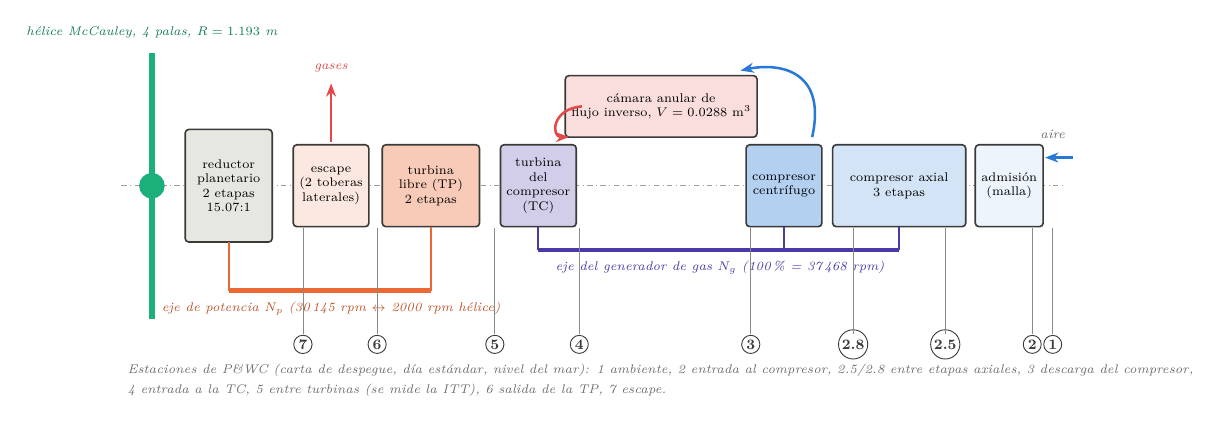

*Figura 1 (TikZ, `docs/figures/tikz/pt6_estaciones.tex`).* El aire entra por detrás (estación 1), avanza hacia la hélice a través de 3 etapas axiales y una centrífuga (3), da media vuelta en la cámara de **flujo inverso** (4), mueve la turbina del compresor y sale hacia la turbina libre (5 → 6) y las toberas de escape (7). La ITT se mide en la estación 5.

Los datos certificados y la carta de estaciones de P&WC son la referencia de todo el cuadernillo:

,Magnitud,Valor,Fuente
0,Potencia de despegue / máx. continua,634 kW (850 shp),TCDS IM.E.078
1,ITT máx. (despegue y continua),800 °C,TCDS
2,ITT máx. en arranque,1000 °C,TCDS
3,Ng 100 % / máximo,37 468 / 39 000 rpm,TCDS
4,Hélice N2 / turbina libre,2000 rpm ↔ 30 145 rpm (15.07:1),TCDS
5,Compresor,3 axiales + 1 centrífugo,TCDS
6,Potencia plana hasta,46 °C ambiente (nivel del mar),TCDS
7,Par de despegue en la hélice,634 kW / 209.4 rad/s = 3027 N·m,calculado


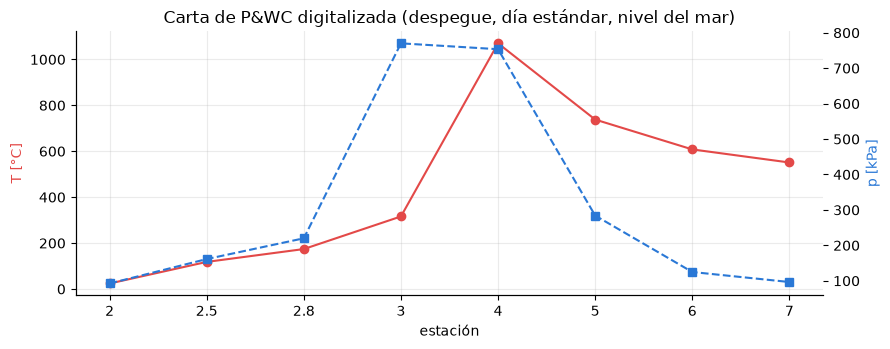

Incertidumbre de lectura: ±8 °C, ±0.8 psia.


In [4]:
CARTA_JSON = json.load(open(os.path.join("data", "pt6_carta_estaciones.json")))
tabla_tcds = pd.DataFrame([
    ("Potencia de despegue / máx. continua", "634 kW (850 shp)", "TCDS IM.E.078"),
    ("ITT máx. (despegue y continua)", "800 °C", "TCDS"), ("ITT máx. en arranque", "1000 °C", "TCDS"),
    ("Ng 100 % / máximo", "37 468 / 39 000 rpm", "TCDS"),
    ("Hélice N2 / turbina libre", "2000 rpm ↔ 30 145 rpm (15.07:1)", "TCDS"),
    ("Compresor", "3 axiales + 1 centrífugo", "TCDS"),
    ("Potencia plana hasta", "46 °C ambiente (nivel del mar)", "TCDS"),
    ("Par de despegue en la hélice", "634 kW / 209.4 rad/s = 3027 N·m", "calculado")],
    columns=["Magnitud", "Valor", "Fuente"])
display(tabla_tcds)
est = CARTA_JSON["estaciones"]
fig, ax = plt.subplots(figsize=(9, 3.6)); ax2 = ax.twinx()
ks = list(est)
ax.plot(ks, [est[k]["T_C"] for k in ks], "o-", color=COL["gas"], label="T [°C]")
ax2.plot(ks, [est[k]["p_psia"]*PSI/1e3 for k in ks], "s--", color=COL["aire"], label="p [kPa]")
ax.set_xlabel("estación"); ax.set_ylabel("T [°C]", color=COL["gas"]); ax2.set_ylabel("p [kPa]", color=COL["aire"])
ax2.grid(False); ax.set_title("Carta de P&WC digitalizada (despegue, día estándar, nivel del mar)")
plt.tight_layout(); plt.show()
print("Incertidumbre de lectura: ±%.0f °C, ±%.1f psia." % (CARTA_JSON["incertidumbre"]["T_C"], CARTA_JSON["incertidumbre"]["p_psia"]))

## 3. Atmósfera y admisión

El PT6 respira aire de la atmósfera estándar (ISA) más la recuperación de presión dinámica en la toma:

$$T(h)=T_0-L\,h,\qquad p(h)=p_0\left(\frac{T}{T_0}\right)^{g/(LR)},\qquad \mu=\mu_0\frac{T^{3/2}}{T+S}\ \text{(Sutherland)}$$

$$h_{02}=h(T)+\tfrac12V^2,\qquad p_{02}=p\,\exp\!\left[\frac{s(T_{s})-s(T)}{R}\right](1-\Delta p_{malla}),\quad h(T_s)=h(T)+\eta_{ram}\tfrac12V^2$$

> 🎓 **Corrección heredada.** La versión original de la ecuación de admisión de la Lección 14 multiplicaba por el exponente $\gamma/(\gamma-1)$ en lugar de elevar a él. Aquí la recuperación se calcula con la entropía de CoolProp, válida para cualquier $V$. Las entregas de 2024 simularon la ruta El Dorado–Guaymaral **desde 0 m**, pero ambos aeropuertos están a unos 2550 m: la densidad es un 23 % menor.

**Widget 1.** Mueve la altitud, la velocidad de vuelo y la desviación ISA. Observa cuánto aire (densidad) le queda al motor en Bogotá.

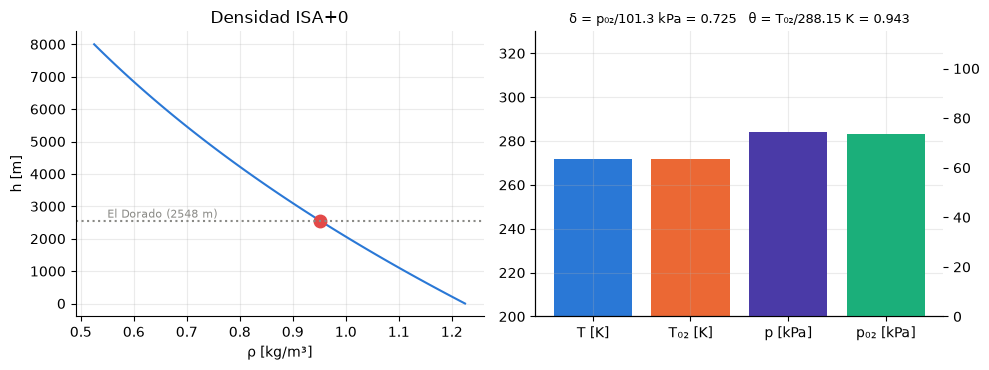

ρ = 0.952 kg/m³ (78 % del nivel del mar)   μ = 1.71e-05 Pa·s


In [5]:
def widget_atm(h=2548.0, V=0.0, dT=0.0):
    hs = np.linspace(0, 8000, 81)
    rhos = [isa(x, dT)[2] for x in hs]
    T0, p0, T, p, rho, mu = admision(h, V, dT)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
    a1.plot(rhos, hs, color=COL["aire"]); a1.plot(rho, h, "o", color=COL["gas"], ms=9)
    a1.axhline(2548, color=COL["gris"], ls=":"); a1.text(0.55, 2650, "El Dorado (2548 m)", fontsize=8, color=COL["gris"])
    a1.set_xlabel("ρ [kg/m³]"); a1.set_ylabel("h [m]"); a1.set_title("Densidad ISA%+.0f" % dT)
    a2.bar(["T [K]", "T₀₂ [K]"], [T, T0], color=[COL["aire"], COL["pt"]])
    a2b = a2.twinx(); a2b.grid(False)
    a2b.bar(["p [kPa]", "p₀₂ [kPa]"], [p/1e3, p0/1e3], color=[COL["gg"], COL["helice"]])
    a2.set_ylim(200, 330); a2b.set_ylim(0, 115)
    a2.set_title("δ = p₀₂/101.3 kPa = %.3f   θ = T₀₂/288.15 K = %.3f" % (p0/101325, T0/288.15), fontsize=9.5)
    plt.tight_layout(); plt.show()
    print("ρ = %.3f kg/m³ (%.0f %% del nivel del mar)   μ = %.2e Pa·s" % (rho, 100*rho/1.225, mu))
w = dict(h=FloatSlider(value=2548, min=0, max=8000, step=100, description="h [m]"),
         V=FloatSlider(value=0, min=0, max=160, step=5, description="V [m/s]"),
         dT=FloatSlider(value=0, min=-20, max=35, step=1, description="ΔT ISA [K]"))
display(VBox([HBox(list(w.values())), interactive_output(widget_atm, w)]))

## 4. Compresor: el mapa sale de los triángulos de velocidad

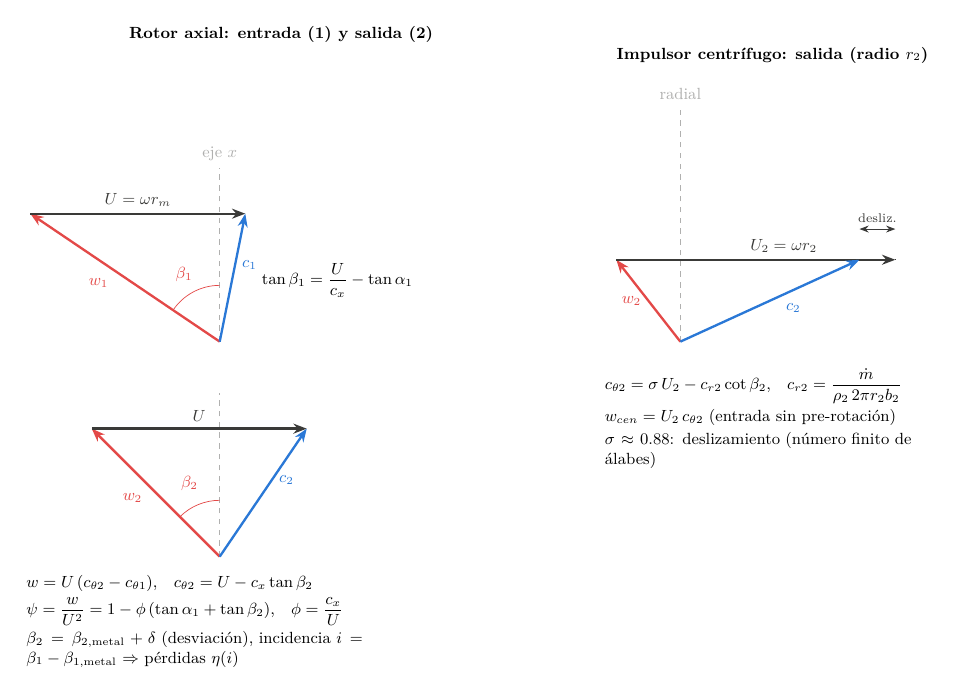

*Figura 2 (TikZ).* En cada rotor el aire llega con velocidad relativa $w_1$ y sale con $w_2$ casi paralela al borde de fuga. La diferencia de **velocidad tangencial absoluta** es el trabajo (Euler):

$$w_{etapa}=U\,(c_{\theta2}-c_{\theta1})=U\,[U-c_x(\tan\alpha_1+\tan\beta_2)]\quad\Longrightarrow\quad \psi=\frac{w}{U^2}=1-\phi\,(\tan\alpha_1+\tan\beta_2),\ \ \phi=\frac{c_x}{U}$$

Tres ingredientes convierten esa recta en un **mapa** real:

- **Continuidad** en cada anillo: $\dot m=\rho_s A\,c_x$ con densidad estática; si $c$ llega a Mach 1 la etapa se **estrangula**.
- **Incidencia** $i=\beta_1-\beta_{1,metal}$ con $\tan\beta_1=U/c_x-\tan\alpha_1$: lejos del diseño, $\eta=\eta_{max}[1-k_i(i-i_d)^2]$. A bajo caudal la etapa 1 se acerca a la **entrada en pérdida** y la línea de velocidad tiene un máximo: el **límite de bombeo**.
- **Impulsor centrífugo** con deslizamiento: $c_{\theta2}=\sigma U_2-c_{r2}\cot\beta_2$, $w=U_2c_{\theta2}$.

La presión de cada etapa sale de la entropía de CoolProp: $h(T_{2s})=h(T_1)+\eta\,w$, $p_2=p_1\exp\{[s(T_{2s})-s(T_1)]/R\}$.

In [6]:
# === Compresor axial-centrífugo por línea media (Euler + continuidad + incidencia) ===
# Ángulos de metal, incidencia y desviación de diseño: Yoshinaka & Thue (1985), rotores 1, 2 y 4.
AX = [dict(rt=0.100, rh=0.072, b1=56.8, b2=50.5, i_d=4.7, dev=3.9),
      dict(rt=0.096, rh=0.076, b1=57.85, b2=43.5, i_d=3.1, dev=5.1),
      dict(rt=0.092, rh=0.080, b1=57.1, b2=36.2, i_d=0.9, dev=5.8)]
CEN = dict(r1=0.092, r2=0.117, b1=0.0201, b2=0.02, beta1=40.0, beta2=38.0)
ALFA_EST = [0.0, 11.0, 12.0]
NG100, NG_MAX = 37468.0, 39000.0
GEO = dict(kr=1.0, eta_max=0.88, ki=6.0, sigma=0.88, eta_cen=0.80, A=[None, None, None])

def cx_continuidad(m, A, T0, p0, ta):
    cpa = AIRE.cpT(T0)
    cmax = math.sqrt(2*cpa*T0*(0.4/2.4)/(1 + ta**2))
    def flujo(cx):
        T = T0 - cx**2*(1 + ta**2)/(2*cpa)
        return p0*(T/T0)**3.5/(R_AIRE*T)*A*cx
    if flujo(cmax) < m:
        return None
    return brentq(lambda c: flujo(c) - m, 1e-3, cmax)

def compresor(N, m, T0, p0, G=GEO, detalle=False, dimensionar=False):
    om = N*2*math.pi/60; kr = G["kr"]; W = 0.0; filas = []; cx1 = None
    for i, s in enumerate(AX):
        rt, rh = s["rt"]*kr, s["rh"]*kr
        rm = 0.5*(rt + rh); U = om*rm
        ta = math.tan(math.radians(ALFA_EST[i]))
        A = G["A"][i] if (G["A"][i] and not dimensionar) else math.pi*(rt**2 - rh**2)
        if dimensionar and i > 0:
            cpa = AIRE.cpT(T0)
            Ts = T0 - cx1**2*(1 + ta**2)/(2*cpa)
            A = m/(p0*(Ts/T0)**3.5/(R_AIRE*Ts)*cx1)
            G["A"][i] = A
        if dimensionar and i == 0:
            G["A"][0] = A
        cx = cx_continuidad(m, A, T0, p0, ta)
        if cx is None:
            return None
        if i == 0: cx1 = cx
        inc = math.degrees(math.atan(U/cx - ta)) - s["b1"]
        w = U*(U - cx*(ta + math.tan(math.radians(s["b2"] + s["dev"]))))
        eta = max(0.30, G["eta_max"]*(1 - G["ki"]*math.radians(inc - s["i_d"])**2))
        if w > 0:
            T1 = AIRE.Th(AIRE.hT(T0) + w); T1s = AIRE.Th(AIRE.hT(T0) + eta*w)
        else:   # etapa que "turbina": la perdida igual degrada presion
            T1 = AIRE.Th(AIRE.hT(T0) + w); T1s = AIRE.Th(AIRE.hT(T0) + w/eta)
        p1 = p0*math.exp((AIRE.sT(T1s) - AIRE.sT(T0))/R_AIRE)
        if detalle:
            filas.append(dict(etapa=f"axial {i+1}", A=A, U=U, cx=cx, phi=cx/U, inc=inc,
                              psi=w/U**2, w=w, eta=eta, T=T1, p=p1))
        T0, p0, W = T1, p1, W + w
    r2, b2 = CEN["r2"]*kr, CEN["b2"]*kr; U2 = om*r2; T2 = T0 + 150.0
    for _ in range(20):
        rho2 = p0*(T2/T0)**3.0/(R_AIRE*T2)
        cr2 = m/(rho2*2*math.pi*r2*b2)
        w = G["sigma"]*U2**2 - U2*cr2/math.tan(math.radians(CEN["beta2"]))
        T2 = AIRE.Th(AIRE.hT(T0) + w)
    T2s = AIRE.Th(AIRE.hT(T0) + G["eta_cen"]*w)
    p2 = p0*math.exp((AIRE.sT(T2s) - AIRE.sT(T0))/R_AIRE)
    if detalle:
        filas.append(dict(etapa="centrífuga", A=2*math.pi*r2*b2, U=U2, cx=cr2, phi=cr2/U2, inc=0.0,
                          psi=w/U2**2, w=w, eta=G["eta_cen"], T=T2, p=p2))
    return dict(W=W + w, T=T2, p=p2, filas=filas)

> 🎓 **Geometría de la entrega.** Radios y ángulos por etapa de la tesis de 2019 (heredados por el manuscrito de 2024). Los ángulos coinciden con los **ángulos de metal** del artículo de P&WC sobre el PT6A-65 (rotor 1: 56.8°/50.5°; rotor 4: 57.1°/36.2°). El PT6A-61 tiene 3 etapas axiales según el TCDS, así que tres etapas es correcto para este motor.
>
> **Hallazgo.** Con esos anillos, **la etapa 3 se estrangula antes de que la etapa 1 alcance su incidencia de diseño**: el anillo de la etapa 3 tiene 12 mm de altura de álabe (área 32 % menor que la necesaria). Es el mismo problema de *emparejamiento de etapas* que describe el artículo de P&WC para el -65. Aquí se corrige con la regla de diseño de ese artículo, **velocidad axial constante en la línea media**: las áreas de las etapas 2 y 3 se dimensionan por continuidad en el punto de diseño.

In [7]:
# === Calibración del punto de diseño contra la carta de P&WC y el TCDS ===
# Incógnitas del compresor: escala radial kr, eficiencia del centrífugo y caudal (T3, p3 e incidencia
# de diseño de la etapa 1). Incógnitas calientes: fracción de enfriamiento ε (ITT) y η de turbinas (634 kW).
try:    # carta de estaciones de P&WC digitalizada (°C, psia): despegue, dia estandar, nivel del mar
    CARTA = {k: (v["T_C"], v["p_psia"]) for k, v in
             json.load(open(os.path.join("data", "pt6_carta_estaciones.json")))["estaciones"].items()}
except FileNotFoundError:
    CARTA = {"2": (24, 13.4), "2.5": (118, 23.4), "2.8": (174, 31.9), "3": (316, 111.7), "4": (1070, 109.3),
             "5": (738, 41.2), "6": (608, 18.1), "7": (551, 14.0)}
TCDS = dict(P_TO=634e3, ITT_max=800.0, ITT_arr=1000.0, Ng100=37468.0, Ng_max=39000.0,
            N2=2000.0, Npt=30145.0, Q_max=3023.0)
G_RED = TCDS["Npt"]/TCDS["N2"]
I_GG, I_PT, I_HEL = 0.12, 0.06, 8.0
V_CC = 0.02882
R_CT, R_PT = 0.5*(0.117 + 0.092), 0.5*(0.5*(0.125 + 0.09) + 0.5*(0.142 + 0.088))
ETA_M, ETA_RED = 0.99, 0.985
D = {}   # parametros de diseno calibrados

def calibrar_compresor():
    T2, p2 = 288.15, 101325.0*(1 - 0.01)
    T3c, p3c = CARTA["3"][0] + 273.15, CARTA["3"][1]*PSI
    def res(x):
        G = dict(GEO); G["A"] = [None]*3; G["kr"], G["eta_cen"], m = x
        r = compresor(NG100, m, T2, p2, G, detalle=True, dimensionar=True)
        if r is None: return [10, 10, 10]
        return [(r["T"] - T3c)/T3c, (r["p"] - p3c)/p3c, (r["filas"][0]["inc"] - AX[0]["i_d"])/10]
    s = least_squares(res, [1.1, 0.8, 3.3], bounds=([0.8, 0.5, 1.0], [1.6, 0.95, 8.0]), xtol=1e-12)
    GEO["A"] = [None]*3; GEO["kr"], GEO["eta_cen"], m = s.x
    r = compresor(NG100, m, T2, p2, GEO, detalle=True, dimensionar=True)
    D.update(m=m, T2=T2, p2=p2, T3=r["T"], p3=r["p"], w_c=r["W"], comp=r)
    return r

def flujo_tobera(pr, g=1.3):
    crit = (2/(g + 1))**(g/(g - 1))
    if pr <= crit: return 1.0
    pr = min(pr, 0.99999)
    f = lambda x: x**(2/g) - x**((g + 1)/g)
    return math.sqrt(f(pr)/f(crit))

def calibrar_caliente(comb=None):
    comb = comb or combustible(1.0)
    m, T3, p3, Wc = D["m"], D["T3"], D["p3"], D["w_c"]*D["m"]
    T4, p4 = CARTA["4"][0] + 273.15, CARTA["4"][1]*PSI
    T5c, p6 = CARTA["5"][0] + 273.15, CARTA["6"][1]*PSI
    h3 = AIRE.hT(T3) + DH_REF
    fc = brentq(lambda f: Gas(comb, f).Th((h3 + f*comb["hf"])/(1 + f)) - T4, 0.002, 0.06)
    P_acc = 8e3
    def mezcla(eps):
        mf = fc*(1 - eps)*m; G = Gas(comb, mf/m)
        h4 = ((1 - eps)*m*(1 + fc)*Gas(comb, fc).hT(T4) + eps*m*h3)/(m + mf)
        dh = (Wc + P_acc)/ETA_M/(m + mf)
        return mf, G, h4, dh
    eps = brentq(lambda e: (lambda r: r[1].Th(r[2] - r[3]))(mezcla(e)) - T5c, 0.0, 0.5)
    mf, G, h4, dh = mezcla(eps); T4m = G.Th(h4); T5 = G.Th(h4 - dh); mg = m + mf
    def pot(eta):
        T5s = G.Th(h4 - dh/eta); p5 = p4/math.exp((G.sT(T4m) - G.sT(T5s))/G.R)
        T6s = G.T_isen(T5, p6/p5); T6 = G.Th(G.hT(T5) - eta*(G.hT(T5) - G.hT(T6s)))
        return mg*(G.hT(T5) - G.hT(T6))*ETA_RED, p5, T6, T6s
    eta_T = brentq(lambda e: pot(e)[0] - TCDS["P_TO"], 0.6, 0.99)
    P, p5, T6, T6s = pot(eta_T)
    T5s = G.Th(h4 - dh/eta_T)
    nu_ct = (2*math.pi*NG100/60*R_CT)/math.sqrt(2*dh/eta_T)
    nu_pt = (2*math.pi*TCDS["Npt"]/60*R_PT)/math.sqrt(2*(G.hT(T5) - G.hT(T6s)))
    p_amb = 101325.0
    D.update(comb=comb, fc=fc, eps=eps, mf=mf, f=mf/m, T4core=T4, T4=T4m, p4=p4, dp_cc=1 - p4/D["p3"],
             T5=T5, p5=p5, T6=T6, p6=p6, eta_T=eta_T, P=P, P_acc=P_acc, mg=mg,
             K4=mg*math.sqrt(T4m)/p4, K45=mg*math.sqrt(T5)/p5, nu_ct=nu_ct, nu_pt=nu_pt,
             kx=(p6 - p_amb)*p_amb/(mg**2*T5), SFC=mf*3600/(P/1e3),
             wf_pb=mf/D["p3"])
    return D

def eta_turbina(nu, nu_d, eta_d):
    x = nu/nu_d
    return eta_d*max(x*(2 - x), -0.5)

In [8]:
# Punto de diseño (despegue, nivel del mar, día estándar; SUPUESTO: Ng = 100 % en la carta de P&WC)
rc = calibrar_compresor()
fil = pd.DataFrame(rc["filas"])
fil["A [cm²]"] = fil["A"]*1e4
tabla_c = fil[["etapa", "A [cm²]", "U", "cx", "phi", "inc", "psi", "w", "eta", "T", "p"]].copy()
tabla_c.columns = ["etapa", "A [cm²]", "U [m/s]", "c_x [m/s]", "φ", "incidencia [°]", "ψ", "w [J/kg]", "η", "T [K]", "p [Pa]"]
display(tabla_c.round(3))
A_entrega = [math.pi*(s["rt"]**2 - s["rh"]**2)*GEO["kr"]**2 for s in AX]
print("Calibrado: kr = %.3f   η_centrífugo = %.3f   ṁ = %.3f kg/s   PR = %.2f" %
      (GEO["kr"], GEO["eta_cen"], D["m"], D["p3"]/D["p2"]))
print("Áreas de las etapas 2 y 3: entrega (×kr²) = %.1f y %.1f cm²; necesarias por continuidad = %.1f y %.1f cm²"
      % (A_entrega[1]*1e4, A_entrega[2]*1e4, GEO["A"][1]*1e4, GEO["A"][2]*1e4))
# demostración del estrangulamiento con los anillos de la entrega
G_ent = dict(GEO); G_ent["A"] = [None]*3
m_lo, m_hi = 0.5, 6.0
for _ in range(40):
    mm = 0.5*(m_lo + m_hi)
    if compresor(NG100, mm, D["T2"], D["p2"], G_ent) is None: m_hi = mm
    else: m_lo = mm
print("Con los anillos de la entrega, a Ng = 100 %% el compresor se estrangula en ṁ = %.2f kg/s (< %.2f de diseño)." % (m_lo, D["m"]))

,etapa,A [cm²],U [m/s],c_x [m/s],φ,incidencia [°],ψ,w [J/kg],η,T [K],p [Pa]
0,axial 1,173.421,361.261,196.149,0.543,4.700,0.242,31532.020,0.880,319.525,138191.693
1,axial 2,137.974,361.261,196.149,0.543,0.891,0.279,36359.590,0.872,355.626,192170.996
2,axial 3,108.664,361.261,196.149,0.543,1.359,0.396,51644.046,0.880,406.697,292201.677
3,centrífuga,168.524,491.483,39.242,0.080,0.000,0.778,187882.705,0.692,589.150,770144.357


Calibrado: kr = 1.071   η_centrífugo = 0.692   ṁ = 3.474 kg/s   PR = 7.68
Áreas de las etapas 2 y 3: entrega (×kr²) = 123.9 y 74.3 cm²; necesarias por continuidad = 138.0 y 108.7 cm²
Con los anillos de la entrega, a Ng = 100 % el compresor se estrangula en ṁ = 3.25 kg/s (< 3.47 de diseño).


El caudal calibrado, 3.47 kg/s, cae dentro del rango publicado para la familia PT6A (2.7–4.3 kg/s). La eficiencia del conjunto centrífugo, 0.69, absorbe las pérdidas del difusor de tubos y de los dos codos de 180° hacia la cámara, que el modelo no separa.

**Widget 2: triángulos de las cuatro etapas.** Cambia $N_g$ y el caudal. Observa:
- A bajo caudal la **incidencia** de la etapa 1 crece y aparece la pérdida.
- A alto caudal la etapa 3 se **estrangula**.
- A menor $N_g$ cae la $U$ de todas las etapas y con ella el trabajo, que crece como $U^2$.

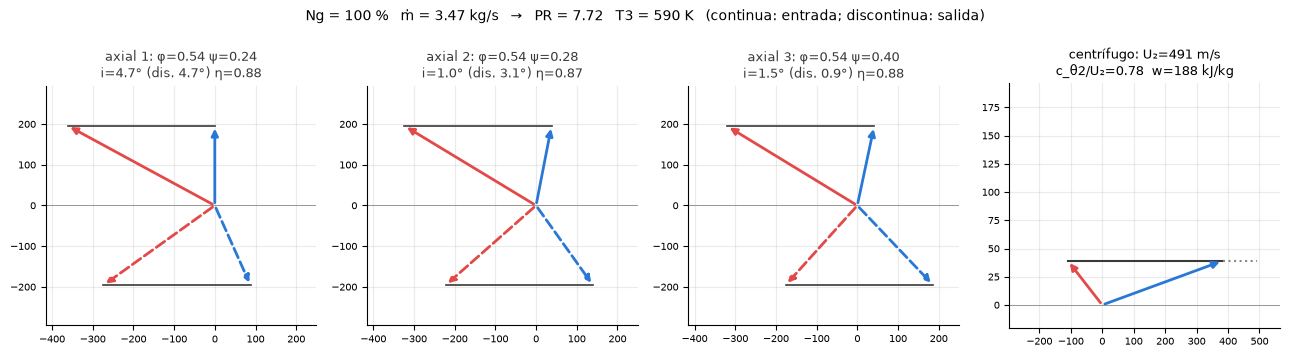

In [9]:
def dibujar_tri(ax, U, cx, ta1, tb2, titulo, color_i):
    c1 = (cx*ta1, cx); w1 = (cx*ta1 - U, cx)
    ct2 = U - cx*tb2; c2 = (ct2, cx); w2 = (ct2 - U, cx)
    for (x, y), col, lw in [(w1, COL["gas"], 2), (c1, COL["aire"], 2)]:
        ax.annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=lw))
    for (x, y), col in [(w2, COL["gas"]), (c2, COL["aire"])]:
        ax.annotate("", xy=(x, -y), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=2, ls="--"))
    ax.plot([w1[0], c1[0]], [cx, cx], color=COL["tinta"], lw=1.2); ax.plot([w2[0], c2[0]], [-cx, -cx], color=COL["tinta"], lw=1.2)
    ax.axhline(0, color=COL["gris"], lw=0.6); ax.set_aspect("equal")
    lim = max(U, 260)*1.15
    ax.set_xlim(-lim, 0.6*lim); ax.set_ylim(-1.3*cx - 40, 1.3*cx + 40)
    ax.set_title(titulo, fontsize=9, color=color_i); ax.tick_params(labelsize=7)
def widget_triangulos(Ng_pct=100.0, m=3.47):
    N = Ng_pct/100*NG100
    r = compresor(N, m, D["T2"], D["p2"], GEO, detalle=True)
    fig, axs = plt.subplots(1, 4, figsize=(13, 3.6))
    if r is None:
        for a in axs: a.axis("off")
        axs[1].text(0.5, 0.5, "ETAPA ESTRANGULADA: el caudal pedido supera\nla capacidad del anillo a esta velocidad", ha="center",
                    transform=axs[1].transAxes, color=COL["aviso"], fontsize=12)
        plt.show(); return
    for k, f in enumerate(r["filas"]):
        if k < 3:
            ta1 = math.tan(math.radians(ALFA_EST[k])); tb2 = math.tan(math.radians(AX[k]["b2"] + AX[k]["dev"]))
            di = f["inc"] - AX[k]["i_d"]
            col = COL["aviso"] if abs(di) > 6 else COL["tinta"]
            dibujar_tri(axs[k], f["U"], f["cx"], ta1, tb2,
                        "%s: φ=%.2f ψ=%.2f\ni=%.1f° (dis. %.1f°) η=%.2f" % (f["etapa"], f["phi"], f["psi"], f["inc"], AX[k]["i_d"], f["eta"]), col)
        else:
            ax = axs[3]; U2, cr = f["U"], f["cx"]; ct = f["w"]/U2
            ax.annotate("", xy=(ct, cr), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=COL["aire"], lw=2))
            ax.annotate("", xy=(ct - U2, cr), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=COL["gas"], lw=2))
            ax.plot([ct - U2, ct], [cr, cr], color=COL["tinta"]); ax.plot([ct, U2], [cr, cr], ":", color=COL["gris"])
            ax.set_xlim(-0.6*U2, 1.15*U2); ax.set_ylim(-20, 4*cr + 40); ax.axhline(0, color=COL["gris"], lw=0.6)
            ax.set_title("centrífugo: U₂=%.0f m/s\nc_θ2/U₂=%.2f  w=%.0f kJ/kg" % (U2, ct/U2, f["w"]/1e3), fontsize=9)
            ax.tick_params(labelsize=7)
    fig.suptitle("Ng = %.0f %%   ṁ = %.2f kg/s   →   PR = %.2f   T3 = %.0f K   (continua: entrada; discontinua: salida)" %
                 (Ng_pct, m, r["p"]/D["p2"], r["T"]), fontsize=10)
    plt.tight_layout(); plt.show()
w2 = dict(Ng_pct=FloatSlider(value=100, min=55, max=104, step=1, description="Ng [%]"),
          m=FloatSlider(value=3.47, min=1.0, max=3.9, step=0.02, description="ṁ [kg/s]"))
display(VBox([HBox(list(w2.values())), interactive_output(widget_triangulos, w2)]))

In [10]:
# === Mapa del compresor (variables corregidas al estándar) e inversión rápida para las EDO ===
def tabular_mapa(Nfr=np.linspace(0.40, 1.06, 23), K=36):
    T2, p2 = 288.15, 101325.0
    tab = dict(Nfr=Nfr, m=[], PR=[], w=[], eta=[], surge=[])
    for nf in Nfr:
        N = nf*NG100
        lo, hi = 0.02, 8.0
        for _ in range(40):      # flujo de estrangulamiento
            mid = 0.5*(lo + hi)
            if compresor(N, mid, T2, p2) is None: hi = mid
            else: lo = mid
        ms = np.linspace(0.08*lo, lo*0.999, 3*K)
        res = [compresor(N, mm, T2, p2) for mm in ms]
        PR = np.array([r["p"]/p2 for r in res]); W = np.array([r["W"] for r in res])
        ks = int(np.argmax(PR))           # pico de la linea de velocidad = limite de bombeo
        mm = np.linspace(ms[ks], ms[-1], K)
        PRk = np.interp(mm, ms, PR); Wk = np.interp(mm, ms, W)
        Ts = np.array([AIRE.Ts(AIRE.sT(T2) + R_AIRE*math.log(p)) for p in PRk])
        etak = (AIRE.hT(Ts) - AIRE.hT(T2))/Wk
        tab["m"].append(mm); tab["PR"].append(PRk); tab["w"].append(Wk); tab["eta"].append(etak)
        tab["surge"].append((ms[ks], PR[ks]))
    for k in ["m", "PR", "w", "eta"]:
        tab[k] = np.array(tab[k])
    return tab

MAPA = {}
def mapa_compresor(Nfr, PR):
    """Inversion del mapa: (N corregida, PR) -> (m corregido, w corregido, eta, bombeo?)."""
    Nf = MAPA["Nfr"]; i = int(np.clip(np.searchsorted(Nf, Nfr) - 1, 0, len(Nf) - 2))
    a = float(np.clip((Nfr - Nf[i])/(Nf[i + 1] - Nf[i]), -0.5, 1.5))
    m = (1 - a)*MAPA["m"][i] + a*MAPA["m"][i + 1]
    pr = (1 - a)*MAPA["PR"][i] + a*MAPA["PR"][i + 1]
    w = (1 - a)*MAPA["w"][i] + a*MAPA["w"][i + 1]
    et = (1 - a)*MAPA["eta"][i] + a*MAPA["eta"][i + 1]
    bombeo = PR > pr[0]
    prr = pr[::-1]
    mc = np.interp(PR, prr, m[::-1]); wc = np.interp(PR, prr, w[::-1]); ec = np.interp(PR, prr, et[::-1])
    return mc, wc, ec, bombeo

In [11]:
t0 = time.time()
MAPA.update(tabular_mapa())
print("Mapa: %d líneas de velocidad tabuladas en %.1f s" % (len(MAPA["Nfr"]), time.time() - t0))

Mapa: 23 líneas de velocidad tabuladas en 1.1 s


## 5. Cámara de combustión 0D: Jet A-1, biodiésel y el aire que no se quema

La cámara anular de flujo inverso es un **volumen de control** de 0.0288 m³ (medido en SolidWorks en la tesis de 2019). Su masa y su energía interna obedecen:

$$\frac{dM}{dt}=\dot m_c+\dot w_f-\dot m_4,\qquad \frac{d(Mu)}{dt}=\dot m_c\,h_3+\dot w_f\,h_f-\dot m_4\,h_4$$

$$\Rightarrow\ \frac{dT}{dt}=\frac{\dot m_c h_3+\dot w_f h_f-\dot m_4 h_4-u\,\dot M}{M\,c_v},\qquad \frac{dp}{dt}=\frac{R}{V}\left(T\dot M+M\dot T\right)$$

con $\dot m_4$ fijado por la tobera de la turbina (§6). La entalpía del combustible $h_f$ se construye para que reproduzca su poder calorífico inferior con las entalpías NASA de Cantera:

$$h_f=\text{LHV}+n_C\,\bar h_{CO_2}+\tfrac{n_H}{2}\,\bar h_{H_2O}-\left(n_C+\tfrac{n_H}{4}-\tfrac{n_O}{2}\right)\bar h_{O_2}\quad(298\ \text{K})$$

> 🎓 **Combustibles de la entrega.** Jet A-1 (LHV 43.1 MJ/kg) y biodiésel (37.52 MJ/kg), con mezclas por fracción másica. SUPUESTO: el biodiésel se representa por su fórmula media (oleato de metilo, C₁₉H₃₆O₂).

**Dilución.** La llama no ve todo el aire. Una fracción $\varepsilon$ enfría la camisa y los álabes guía y se mezcla antes del rotor de la turbina del compresor. La carta de P&WC da $T_4=1070$ °C (zona de llama) e ITT $=738$ °C. Con el trabajo del compresor, el balance de energía solo cierra si $\varepsilon\approx11$ %, que se calibra en §6.

In [12]:
# V4: poder calorífico del Jet-A(g) de la base NASA de Cantera contra la especificación
lhv_spec = 43.1e6
err_lhv = 100*(LHV_JETA_VAP - lhv_spec)/lhv_spec
print("LHV Jet-A(g), NASA/Cantera (vapor): %.2f MJ/kg   especificación (líquido): %.2f MJ/kg   diferencia: %+.2f %%"
      % (LHV_JETA_VAP/1e6, lhv_spec/1e6, err_lhv))
print("La diferencia es del orden del calor latente de vaporización del queroseno (~0.25-0.36 MJ/kg).")
def llama(x_jet, f, T3=589.15):
    cb = combustible(x_jet)
    G = Gas(cb, f)
    T = float(G.Th((AIRE.hT(T3) + DH_REF + f*cb["hf"])/(1 + f)))
    return cb, G, T
filas = []
for x in [1.0, 0.75, 0.5, 0.0]:
    cb = combustible(x)
    f_st = 1/cb["AFst"]
    _, _, T_ad = llama(x, 0.6*f_st)
    filas.append(dict(mezcla="Jet A-1 %.0f %% / biodiésel %.0f %%" % (100*x, 100*(1 - x)), **{"LHV [MJ/kg]": cb["LHV"]/1e6,
                 "AF estequiom.": cb["AFst"], "T llama φ=0.6 [K]": T_ad, "kg comb. por MJ": 1e6/cb["LHV"]}))
display(pd.DataFrame(filas).round(3))

LHV Jet-A(g), NASA/Cantera (vapor): 43.35 MJ/kg   especificación (líquido): 43.10 MJ/kg   diferencia: +0.58 %
La diferencia es del orden del calor latente de vaporización del queroseno (~0.25-0.36 MJ/kg).


,mezcla,LHV [MJ/kg],AF estequiom.,T llama φ=0.6 [K],kg comb. por MJ
0,Jet A-1 100 % / biodiésel 0 %,43.100,14.670,1922.548,0.023
1,Jet A-1 75 % / biodiésel 25 %,41.705,14.151,1923.958,0.024
2,Jet A-1 50 % / biodiésel 50 %,40.310,13.632,1925.470,0.025
3,Jet A-1 0 % / biodiésel 100 %,37.520,12.593,1928.845,0.027


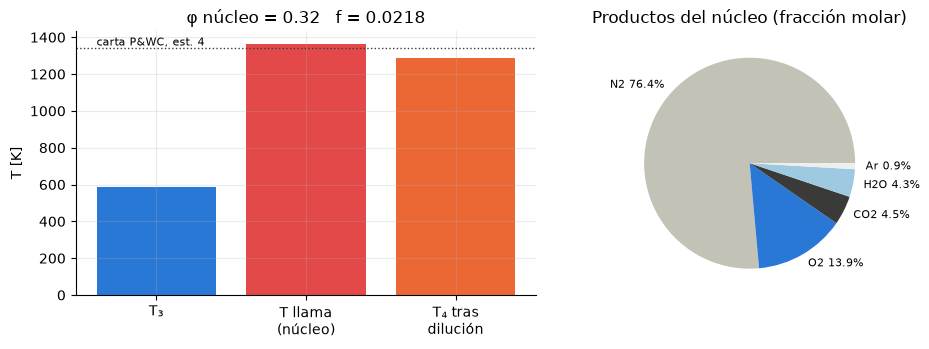

LHV = 43.10 MJ/kg  → para el mismo calor se necesita 0.0 % más combustible que con Jet A-1.


In [13]:
def widget_llama(x_jet=1.0, phi=0.32, eps=11.0):
    cb = combustible(x_jet); f_st = 1/cb["AFst"]
    fc = phi*f_st; T3 = D["T3"]
    _, Gc, Tc = llama(x_jet, fc, T3)
    e = eps/100; m = 1.0; mf = fc*(1 - e)*m
    Gm = Gas(cb, mf/m)
    h4 = ((1 - e)*(1 + fc)*Gc.hT(Tc) + e*(AIRE.hT(T3) + DH_REF))/(1 + mf)
    T4 = float(Gm.Th(h4))
    n = prod_mol = {"N2": N_AIRE["N2"], "O2": N_AIRE["O2"] - fc*(cb["C"] + cb["H"]/4 - cb["O"]/2),
                    "CO2": N_AIRE["CO2"] + fc*cb["C"], "H2O": fc*cb["H"]/2, "Ar": N_AIRE["Ar"]}
    nt = sum(n.values())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
    a1.bar(["T₃", "T llama\n(núcleo)", "T₄ tras\ndilución"], [T3, Tc, T4], color=[COL["aire"], COL["gas"], COL["pt"]])
    a1.axhline(1070 + 273.15, color=COL["tinta"], ls=":", lw=1); a1.text(-0.4, 1355, "carta P&WC, est. 4", fontsize=8)
    a1.set_ylabel("T [K]"); a1.set_title("φ núcleo = %.2f   f = %.4f" % (phi, fc))
    a2.pie([n[k]/nt for k in n], labels=["%s %.1f%%" % (k, 100*n[k]/nt) for k in n],
           colors=["#c3c2b7", "#2a78d6", "#3a3a38", "#9ecae1", "#eeeeee"], textprops=dict(fontsize=8))
    a2.set_title("Productos del núcleo (fracción molar)")
    plt.tight_layout(); plt.show()
    print("LHV = %.2f MJ/kg  → para el mismo calor se necesita %.1f %% más combustible que con Jet A-1."
          % (cb["LHV"]/1e6, 100*(43.1e6/cb["LHV"] - 1)))
w4 = dict(x_jet=FloatSlider(value=1.0, min=0, max=1, step=0.05, description="fracción Jet"),
          phi=FloatSlider(value=0.32, min=0.15, max=0.6, step=0.01, description="φ núcleo"),
          eps=FloatSlider(value=11, min=0, max=25, step=1, description="ε dilución [%]"))
display(VBox([HBox(list(w4.values())), interactive_output(widget_llama, w4)]))

## 6. Turbinas: toberas estranguladas y la turbina libre

Las dos turbinas tienen **álabes guía (toberas)** a la entrada. Cuando la relación de presión supera la crítica, la tobera se **estrangula** y el caudal depende solo de las condiciones aguas arriba:

$$\dot m=K\,\frac{p_0}{\sqrt{T_0}}\,\Phi\!\left(\frac{p_{aguas\ abajo}}{p_0}\right),\qquad \Phi=1\ \text{si}\ \frac{p}{p_0}\le\left(\frac{2}{\gamma+1}\right)^{\gamma/(\gamma-1)}$$

Con las dos toberas estranguladas, la relación de presión de la **turbina del compresor** queda casi fija. Eso explica la relación constante $R_p=3.03$ que usaron las entregas y que aquí aparece sola.

La eficiencia depende de la **relación de velocidades** $\nu=U/c_0$, con $c_0=\sqrt{2\Delta h_s}$. Para una etapa de impulso-reacción, Euler da $w\propto U(a-U)$, es decir:

$$\eta(\nu)=\eta_d\,x\,(2-x),\quad x=\nu/\nu_d\qquad\Longrightarrow\qquad \tau_{TP}=\frac{\dot m\,\eta\,\Delta h_s}{\omega_p}\propto(2-x)$$

**El par de la turbina libre es máximo con la hélice frenada** (el doble del de diseño) y cae linealmente con $N_p$. Por eso el turbohélice arranca con la hélice parada y por eso el eje de potencia **se estabiliza solo**: si se acelera, su par baja; si se frena, sube.

,parámetro,valor,origen
0,FAR del núcleo f_c (T4 = 1070 °C),0.021159,carta
1,Dilución/enfriamiento ε,0.11167,ITT = 738 °C
2,T4 tras dilución [°C],993.92559,calculado
3,η turbinas (TC y TP),0.912264,634 kW (TCDS)
4,p5 calculada [kPa],264.870946,predicción
5,T6 calculada [°C],581.41858,predicción
6,ṁ combustible [kg/s],0.065292,resultado
7,SFC [kg/(kW·h)],0.370742,resultado
8,ν diseño TC / TP,0.500 / 0.556,resultado


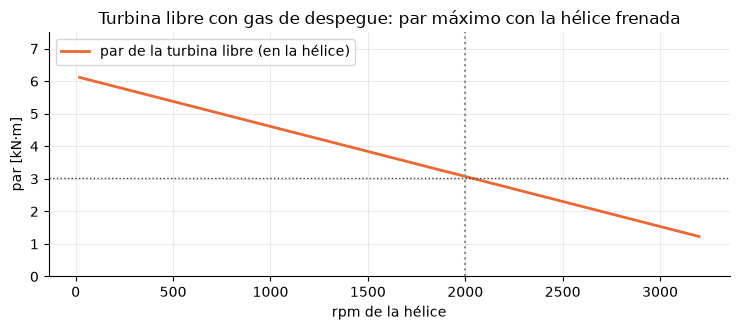

In [14]:
calibrar_caliente()
tab = pd.DataFrame([
    ("FAR del núcleo f_c (T4 = 1070 °C)", D["fc"], "carta"), ("Dilución/enfriamiento ε", D["eps"], "ITT = 738 °C"),
    ("T4 tras dilución [°C]", D["T4"] - 273.15, "calculado"), ("η turbinas (TC y TP)", D["eta_T"], "634 kW (TCDS)"),
    ("p5 calculada [kPa]", D["p5"]/1e3, "predicción"), ("T6 calculada [°C]", D["T6"] - 273.15, "predicción"),
    ("ṁ combustible [kg/s]", D["mf"], "resultado"), ("SFC [kg/(kW·h)]", D["SFC"], "resultado"),
    ("ν diseño TC / TP", "%.3f / %.3f" % (D["nu_ct"], D["nu_pt"]), "resultado")], columns=["parámetro", "valor", "origen"])
display(tab)
# Característica de la turbina libre: par contra Np con el gas del punto de diseño
G = gas(D["comb"], D["f"])
dhs = float(G.hT(D["T5"]) - G.hT(G.T_isen(D["T5"], D["p6"]/D["p5"])))
Np = np.linspace(0.01, 1.6, 120)*TCDS["Npt"]
tau = [D["mg"]*eta_turbina((2*math.pi*n/60*R_PT)/math.sqrt(2*dhs), D["nu_pt"], D["eta_T"])*dhs/(2*math.pi*n/60)*G_RED
       for n in Np]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(Np/G_RED, np.array(tau)/1e3, color=COL["pt"], lw=2, label="par de la turbina libre (en la hélice)")
ax.axvline(2000, color=COL["gris"], ls=":"); ax.axhline(TCDS["Q_max"]/1e3, color=COL["tinta"], ls=":", lw=1)
ax.set_xlabel("rpm de la hélice"); ax.set_ylabel("par [kN·m]"); ax.set_ylim(0, 7.5); ax.legend()
ax.set_title("Turbina libre con gas de despegue: par máximo con la hélice frenada")
plt.tight_layout(); plt.show()

## 7. La hélice McCauley con el método de Traub

La teoría de elemento de pala con cantidad de movimiento (BEMT, Lección 14 §10) exige **iterar** los factores de inducción $a$, $a'$. Esa iteración de punto fijo no converge de forma robusta: la Lección 14 tuvo que abandonarla. Traub (2016) cierra el problema **sin iterar**. Con la teoría de vórtices de Phillips, el ángulo inducido $\alpha_i$ sale de una **cuadrática** en cada estación, e incluye pérdida de punta de Prandtl $F$ y un modelo de entrada en pérdida:

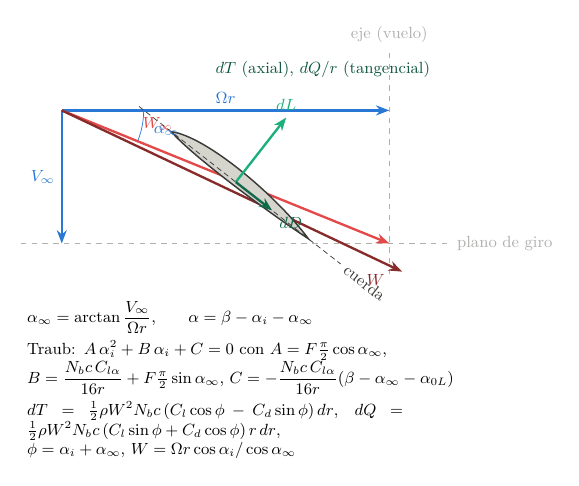

$$X=\frac{1}{1+e^{\sigma(\alpha-\alpha_{st})}},\qquad C_l=C_{l\alpha}(\alpha-\alpha_{0L})\left[\frac{1+X^{m}}{2}\right]^2,\qquad C_d=X\,[C_{d,min}+K_p(C_l-C_{l,md})^2]+(1-X)\,[C_l\tan\alpha+\tfrac12 C_{d,min}]$$

$$T=\frac{N_b\rho\,\Omega^2}{2}\int r^2c\,\frac{\cos^2\alpha_i}{\cos^2\alpha_\infty}\,(C_l\cos\phi-C_d\sin\phi)\,dr,\qquad Q=\frac{N_b\rho\,\Omega^2}{2}\int r^3c\,\frac{\cos^2\alpha_i}{\cos^2\alpha_\infty}\,(C_l\sin\phi+C_d\cos\phi)\,dr$$

> 🎓 **La hélice real, medida.** Castellanos-Proaños, Bayona-Roa, López Gómez y García-Navarro escanearon en 3D la McCauley de 4 palas ($R=1.193$ m) de un PT6A-61 en banco (artículo AIAA, en preparación).
> - **Geometría:** cuerda y paso locales $c(r/R)$, $\beta(r/R)$ de la Fig. 5b. El paso de referencia se mide en $r/R=0.638$, la estación de 30 in. Hay 4 pasos de operación con su par (Tabla 1), simulados con RANS en Fluent (Fig. 13).
> - **Datos XFOIL por sección:** $C_{l\alpha}$, $\alpha_{0L}$ y los ajustes de $C_{d,min}$, $K_p$, $C_{l,md}$ contra Re. Están en el bloque Simulink de la entrega de 2024.
> - **Parámetros de Traub ajustados contra el CFD:** $\sigma=0.9$, $m=0.3$, $\alpha_{st}=20.6°$.
>
> Este cuadernillo usa todo eso **sin ajustar ningún parámetro de la hélice**. Solo hay dos decisiones declaradas (SUPUESTO):
> 1. $\alpha_{0L}$ por sección con signo negativo. La entrega los da positivos; el promedio del artículo es −3.8°.
> 2. Re de los ajustes recortado a 5×10⁵, porque los polinomios de grado 6 divergen más allá.

In [15]:
# === Hélice McCauley: Traub (2016) con la caracterización XFOIL de la entrega ===
# Geometría (Fig. 5b), alpha_st = 20.6°, sigma = 0.9/° y m = 0.3: artículo McCauley. alpha_0L por sección
# (signo negativo) y ajustes XFOIL de la entrega 2024, con Re recortado a 5e5. Ningún parámetro calibrado.
R_P, B_P, R_HUB, R30 = 1.193, 4, 0.25, 0.762
NS = 20
SEC = np.linspace(0, 1, 5)
CLA5 = np.array([0.0846, 0.07462, 0.07911, 0.08, 0.09759])*180/np.pi
AZL5 = -np.radians([7.505656337, 7.779161701, 7.933172122, 5.95941933, 4.0123542])
AST5_ENTREGA = np.radians([14, 12, 6.1059, 5.03731, 4.6125])
AST5 = np.full(5, np.radians(20.6))   # articulo McCauley: alpha_stall efectivo (ajustado contra CFD)
KP5 = [[2.16E-37,-1.11E-30,2.28E-24,-2.35E-18,1.27E-12,-3.45E-07,4.71E-02],[7.20E-38,-3.81E-31,8.10E-25,-8.84E-19,5.29E-13,-1.79E-07,4.06E-02],[6.99E-38,-4.12E-31,9.53E-25,-1.10E-18,6.65E-13,-2.10E-07,4.02E-02],[5.99E-38,-4.00E-31,1.04E-24,-1.34E-18,8.90E-13,-3.01E-07,5.36E-02],[1.87E-38,-1.34E-31,3.76E-25,-5.22E-19,3.71E-13,-1.28E-07,2.54E-02]]
CDM5 = [[3.58E-37,-1.80E-30,3.55E-24,-3.43E-18,1.68E-12,-3.80E-07,4.08E-02],[2.61E-37,-1.32E-30,2.62E-24,-2.59E-18,1.33E-12,-3.35E-07,4.05E-02],[1.33E-37,-7.51E-31,1.67E-24,-1.85E-18,1.06E-12,-2.99E-07,3.96E-02],[2.23E-38,-1.52E-31,4.11E-25,-5.60E-19,4.08E-13,-1.56E-07,3.21E-02],[2.62E-38,-1.85E-31,5.06E-25,-6.78E-19,4.59E-13,-1.47E-07,2.54E-02]]
CLM5 = [[7.64E-36,-3.55E-29,6.37E-23,-5.64E-17,2.61E-11,-6.01E-06,1.03E+00],[-1.02E-36,5.04E-30,-8.94E-24,6.63E-18,-1.54E-12,-5.05E-07,8.86E-01],[-2.76E-36,1.29E-29,-2.24E-23,1.80E-17,-6.48E-12,5.43E-07,7.77E-01],[-5.53E-37,3.39E-30,-7.86E-24,8.61E-18,-4.53E-12,9.75E-07,7.18E-01],[1.49E-37,-5.22E-31,-2.95E-25,3.16E-18,-4.49E-12,2.46E-06,-6.54E-02]]
RE_MAX = 5e5
r_p = np.linspace(R_HUB, 0.97*R_P, NS); x_p = r_p/R_P; dr_p = np.gradient(r_p)
xs_p = (r_p - R_HUB)/(r_p[-1] - R_HUB)
# geometria medida (escaneo 3D, Fig. 5b del articulo McCauley): cuerda y paso local contra r/R
try:
    MCC = json.load(open(os.path.join("data", "mccauley_cfd.json")))
except FileNotFoundError:
    MCC = {"fig5b": {"r_R": [0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.97],
                     "cuerda_m": [0.100, 0.135, 0.155, 0.172, 0.175, 0.174, 0.169, 0.157, 0.140, 0.118],
                     "paso_deg": [58.5, 49.0, 42.0, 36.0, 31.0, 27.8, 23.9, 20.0, 16.0, 13.5]}}
_f5 = MCC["fig5b"]
cuerda = np.interp(x_p, _f5["r_R"], _f5["cuerda_m"])
torsion_med = np.radians(np.interp(x_p, _f5["r_R"], _f5["paso_deg"]) - np.interp(R30/R_P, _f5["r_R"], _f5["paso_deg"]))
_Wint = np.array([np.interp(xs_p, SEC, np.eye(5)[k]) for k in range(5)])   # (5, NS)
cla_p, azl_p = CLA5 @ _Wint, AZL5 @ _Wint
HEL = dict(d0=0.0, sigma=0.9, m=0.3, ast=AST5 @ _Wint)   # sigma (por grado) y m: articulo McCauley

def _coef(P, Re):
    Rc = np.clip(Re, 5e3, RE_MAX)
    V = np.array([np.polyval(p, Rc) for p in P])     # (5, NS)
    return np.einsum("kj,kj->j", V, _Wint)

def torsion(beta_ref):
    # paso local = paso de referencia (r/R = 0.638) + torsion medida
    return np.radians(beta_ref) + torsion_med

def traub(Omega, V, beta30, rho, mu, H=HEL, detalle=False, entrega=False, sigma=None, mexp=None):
    """Modelo de Traub (BEMT no iterativo). entrega=True reproduce los 4 errores del bloque Simulink."""
    Omega = max(Omega, 1.0)
    sigma = (1.5 if entrega else H["sigma"]) if sigma is None else sigma
    mexp = (1.5 if entrega else H["m"]) if mexp is None else mexp
    th = torsion(beta30 + H["d0"])
    ainf = np.arctan2(V, Omega*r_p)
    btip = max(math.atan2(V, Omega*R_P), 0.02)
    if entrega:
        F = (2/np.pi)*np.arccos(np.exp(-B_P*(1 - x_p)/2*math.sin(btip)))
        ast = AST5_ENTREGA @ _Wint
    else:
        F = (2/np.pi)*np.arccos(np.exp(-B_P*(1 - x_p)/(2*math.sin(btip))))
        ast = H["ast"]
    k = B_P*cuerda*cla_p/(16*r_p)
    A = F*np.pi/2*np.cos(ainf); Bq = k + F*np.pi/2*np.sin(ainf); C = -k*(th - ainf - azl_p)
    ai = (-Bq + np.sqrt(np.maximum(Bq**2 - 4*A*C, 0.0)))/(2*A)
    al = th - ai - ainf
    if entrega:
        X = 1/(1 + np.exp(sigma*(al - ast)))            # sigma aplicado en radianes
    else:
        X = 1/(1 + np.exp(sigma*np.degrees(al - ast)))  # sigma por grado (Traub)
    cl = cla_p*(al - azl_p)*((1 + X**mexp)/2)**2
    Re = Omega*r_p*np.cos(ai)*rho*cuerda/(np.cos(ainf)*mu)
    cdmin, kp, clmd = _coef(CDM5, Re), _coef(KP5, Re), _coef(CLM5, Re)
    cd = X*(cdmin + kp*(cl - clmd)**2) + (1 - X)*(cl*np.tan(al) + 0.5*cdmin)
    phi = ai + ainf; fac = np.cos(ai)**2/np.cos(ainf)**2
    K = B_P*rho*Omega**2/2
    if entrega:
        clx = np.where(np.abs(cl) < 1e-3, 1e-3, cl)
        dT = r_p**2*cuerda*fac/clx*(np.cos(phi) - cd/clx*np.sin(phi))
        dQ = r_p**3*cuerda*fac/clx*(np.sin(phi) + cd/clx*np.cos(phi))
        pT, pQ = np.polyfit(r_p, dT, 2), np.polyfit(r_p, dQ, 2)
        a, b = r_p[0], r_p[-1]
        T = K*(pT[0]*(b**2 - a**2)/2 + pT[1]*(b - a))
        Q = K*(pQ[0]*(b**2 - a**2)/2 + pQ[1]*(b - a))
    else:
        dT = r_p**2*cuerda*fac*(cl*np.cos(phi) - cd*np.sin(phi))
        dQ = r_p**3*cuerda*fac*(cl*np.sin(phi) + cd*np.cos(phi))
        T = K*np.sum(dT*dr_p); Q = K*np.sum(dQ*dr_p)
    if detalle:
        return dict(T=T, Q=Q, al=al, ai=ai, ainf=ainf, th=th, cl=cl, cd=cd, F=F, X=X, Re=Re,
                    dT=K*dT, dQ=K*dQ)
    return T, Q

def validar_helice():
    # par del modelo en las condiciones de la Tabla 1 del articulo McCauley, contra su CFD (Fig. 13)
    Om = 2000*2*math.pi/60; n = 2000/60; filas = []
    for caso, c in MCC.get("tabla1", {}).items():
        for k, J in enumerate(c["J"]):
            mu = 1.79e-5*(c["rho"]/1.225)**0.3
            T, Q = traub(Om, J*n*2*R_P, c["beta"], c["rho"], mu)
            filas.append(dict(caso=caso, beta=c["beta"], rho=c["rho"], J=J, Q_modelo=Q,
                              Q_CFD=MCC["fig13_CFD_Q"][caso][k], Q_BEM_articulo=MCC["fig13_BEM_Q"][caso][k]))
    return filas

In [16]:
# === Réplica literal del bloque MATLAB Function de la entrega (para comparar) ===
def traub_entrega(Omega, V, ajuste, rho, mu):
    """Replica literal del bloque MATLAB de la entrega (intento_50metrosporsegundo.slx)."""
    B, Rmax, Rb, nd = 4, 0.9, 0.2, 10
    PALA = np.arange(Rb, Rmax + 1e-9, (Rmax - Rb)/nd)
    r = PALA[:nd]
    TH = np.radians(np.linspace(ajuste, 34.5 + ajuste, nd))
    sec = np.linspace(0, 4, nd)
    azl = np.polyval(np.polyfit(np.arange(5), np.radians([7.505656337, 7.779161701, 7.933172122, 5.95941933, 4.0123542]), 4), sec)
    cla = np.polyval(np.polyfit(np.arange(5), np.array([0.0846, 0.07462, 0.07911, 0.08, 0.09759])*180/np.pi, 4), sec)
    ast = np.polyval(np.polyfit(np.arange(5), np.radians([14, 12, 6.1059, 5.03731, 4.6125]), 4), sec)
    def poli(P):
        cols = []
        for i in range(7):
            cols.append(np.polyval(np.polyfit(np.arange(5), [P[j][i] for j in range(5)], 4), sec))
        return np.array(cols).T
    Kp, Cdm, Clm = poli(KP5), poli(CDM5), poli(CLM5)
    xb = r/Rmax
    c = 0.683*xb**5 - 3.6366*xb**4 + 6.4743*xb**3 - 5.4877*xb**2 + 2.2428*xb - 0.177
    F = (2/np.pi)*np.arccos(np.exp((-B*(1 - r/Rmax))/2*np.sin(TH[-1])))
    ainf = np.arctan(V/(r*Omega))
    A = F*np.pi/2*np.cos(ainf); Bq = B*c*cla/(16*r) + F*np.pi*np.sin(ainf)/2
    C = -B*c*cla*(TH - ainf - azl)/(16*r)
    ai = (-Bq + np.sqrt(Bq**2 - 4*A*C))/(2*A)
    al = TH - ai - ainf
    X = 1/(1 + np.exp(1.5*(al - ast)))
    cl = cla*al*((1 + X**1.5)/2)**2
    Re = Omega*r*np.cos(ai)*rho*c/(np.cos(ainf)*mu)
    kp = np.array([np.polyval(Kp[i], Re[i]) for i in range(nd)])
    cdm = np.array([np.polyval(Cdm[i], Re[i]) for i in range(nd)])
    clm = np.array([np.polyval(Clm[i], Re[i]) for i in range(nd)])
    cd = X*(cdm + kp*(cl - clm)**2) + (1 - X)*(cl*np.tan(al) + 0.5*cdm)
    i1 = (r**3*c*np.cos(ai)**2/(np.cos(ainf)**2*cl))*(np.sin(ai + ainf) + cd/cl*np.cos(ai + ainf))
    i2 = (r**2*c*np.cos(ai)**2/(np.cos(ainf)**2*cl))*(np.cos(ai + ainf) - cd/cl*np.sin(ai + ainf))
    p, q = np.polyfit(r, i1, 2), np.polyfit(r, i2, 2)
    a, b = r[0], r[-1]
    K = B*rho*Omega**2/2
    Q = K*(p[0]*(b**2 - a**2)/2 + p[1]*(b - a)); T = K*(q[0]*(b**2 - a**2)/2 + q[1]*(b - a))
    return dict(T=T, Q=Q, r=r, al=al, cl=cl, cd=cd, X=X, Re=Re, F=F, TH=TH, clm=clm, cdm=cdm)

> 🎓 **Hallazgos en el bloque Traub de la entrega** (`intento_50metrosporsegundo.slx`, código MATLAB embebido). Todos se verifican con la réplica literal de arriba:
> 1. En los integrandos de empuje y par, **$C_l$ divide** en vez de multiplicar: `.../(cos(ALFA_INF)^2*CL_CORRECCION)`. Cuando $C_l\to0$ en la raíz (al crecer $V$), el par diverge y cambia de signo.
> 2. La pérdida de punta se escribe `exp(-B(1-r/R))/2*sin(θ)`: **multiplica** por $\sin$ en lugar de dividir por $2\sin\beta_{tip}$.
> 3. Se ajusta un polinomio de grado 2 al integrando, pero se integra `p(1)*r + p(2)`: una **recta con los coeficientes cruzados**.
> 4. $\sigma=1.5$ se aplica a ángulos **en radianes**: $X\approx0.3$–$0.6$ para cualquier $\alpha$, así que el modelo de pérdida no actúa. Contra el CFD del artículo funciona mejor $\sigma$ por grado.
> 5. Geometría:
>    - el código usa $R=0.9$ m, cuando la hélice mide 1.193 m;
>    - la torsión **crece** de raíz a punta (+34.5°), cuando la medida del artículo (Fig. 5b) baja de 58° a 13°;
>    - $\alpha_{0L}$ es positivo.
> 6. Datos de pérdida: la entrega usa los $\alpha_{st}$ 2D de XFOIL, 4.6–14°, coherentes con la Fig. 9 del artículo, donde $C_{l,max}$ cae entre 5° y 9.5° a Re = 10⁶. Pero en la pala que gira la pérdida se **retrasa** (efecto rotacional 3D): el artículo usa $\alpha_{st}=20.6°$ efectivo, ajustado contra su CFD. Además, los ajustes de grado 6 **divergen** fuera de su rango ($C_{l,md}=14$ en Re = 2×10⁶).
>
> El "límite de 60 m/s" que reporta el manuscrito no es físico: es la singularidad del hallazgo 1.

In [17]:
rho0, mu0 = isa(0)[2:]
Om0 = TCDS["N2"]*2*math.pi/60
filas = []
for V in [2, 20, 40, 50, 60, 80, 120]:
    de = traub_entrega(Om0, V, 32.0, rho0, mu0)
    T, Q = traub(Om0, V, 32.0, rho0, mu0)
    filas.append({"V [m/s]": V, "T entrega [N]": de["T"], "Q entrega [N·m]": de["Q"],
                  "T corregido [N]": T, "Q corregido [N·m]": Q, "η corregido": V*T/(Q*Om0) if T > 0 and Q > 0 else np.nan})
display(pd.DataFrame(filas).round(1))
print("Con β fijo en 32°, a 120 m/s la hélice corregida pasa a molinete (T < 0): por eso el gobernador sube el paso al acelerar.")

,V [m/s],T entrega [N],Q entrega [N·m],T corregido [N],Q corregido [N·m],η corregido
0,2,10705.0,3746.0,13285.9,2990.8,0.0
1,20,10314.8,4396.4,12422.4,3137.7,0.4
2,40,26384.6,7202.8,10435.6,3210.7,0.6
3,50,613668.0,-470677.7,9288.8,3153.2,0.7
4,60,50023.0,15421.6,8089.3,3018.6,0.8
5,80,70583.2,27204.1,5552.6,2483.5,0.9
6,120,14473.4,237589.7,-27.3,169.4,NaN


Con β fijo en 32°, a 120 m/s la hélice corregida pasa a molinete (T < 0): por eso el gobernador sube el paso al acelerar.


**V3: la hélice contra el CFD del artículo.** Se evalúa en las 20 condiciones de la Tabla 1 del artículo (paso, densidad y $J$), a 2000 rpm, y se compara con:
- el par RANS de la Fig. 13;
- el BEMT-Traub del propio artículo;
- un dato estático extra: el estudio de malla (Tabla 2), con $\beta=22°$ y $J\approx0$, da $Q=1576$–$1604$ N·m.

Ningún dato de estas tablas entró en el modelo.

> **Nota de lectura.** En la Fig. 13 del artículo los rótulos de baja y alta altitud están intercambiados respecto a la Tabla 1. Aquí las barras se asignan por $J$, que sí es coherente con $V$, $\rho$ y 2000 rpm. El $J=0.009$ del rodaje se lee como 0.090.

,Q_CFD,Q_modelo,Q_BEM_articulo,error modelo [%],error BEM artículo [%]
caso,,,,,
rodaje,1600.0,1570.9,1810.0,-1.8,13.1
despegue,3006.0,3161.7,3944.0,5.2,31.2
crucero_baja_FL220,2538.0,1561.6,1364.0,-38.7,-46.6
crucero_alta_FL350,2518.0,1840.5,1932.0,-26.9,-23.3


Estático β = 22°: modelo 1537 N·m, CFD 1576-1604 N·m (-2.5 % contra la malla fina)
RMS contra CFD: este modelo 23.8 %, BEMT del artículo 31.2 %


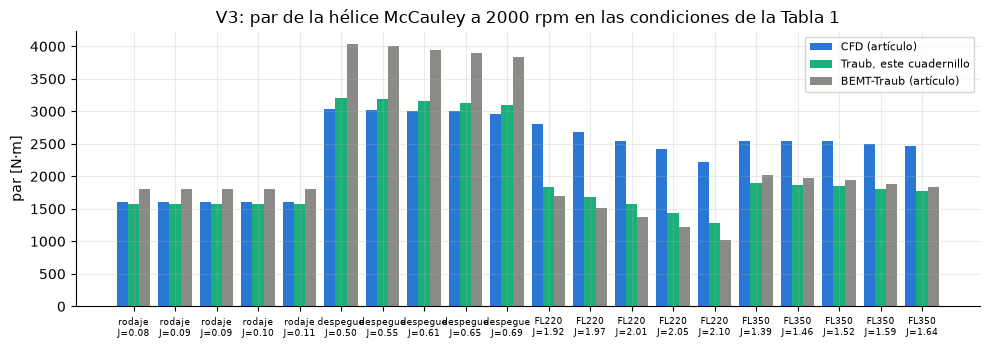

In [18]:
VAL = pd.DataFrame(validar_helice())
VAL["error modelo [%]"] = 100*(VAL["Q_modelo"]/VAL["Q_CFD"] - 1)
VAL["error BEM artículo [%]"] = 100*(VAL["Q_BEM_articulo"]/VAL["Q_CFD"] - 1)
resumen = VAL.groupby("caso", sort=False)[["Q_CFD", "Q_modelo", "Q_BEM_articulo", "error modelo [%]", "error BEM artículo [%]"]].mean()
display(resumen.round(1))
Qs = traub(Om0, 0.0, 22.0, 1.225, 1.79e-5)[1]
print("Estático β = 22°: modelo %.0f N·m, CFD %.0f-%.0f N·m (%+.1f %% contra la malla fina)" % (Qs, 1576, 1604, 100*(Qs/1576 - 1)))
print("RMS contra CFD: este modelo %.1f %%, BEMT del artículo %.1f %%" %
      (np.sqrt((VAL["error modelo [%]"]**2).mean()), np.sqrt((VAL["error BEM artículo [%]"]**2).mean())))
fig, ax = plt.subplots(figsize=(10, 3.6)); x = np.arange(len(VAL))
ax.bar(x - 0.27, VAL["Q_CFD"], 0.27, color=COL["aire"], label="CFD (artículo)")
ax.bar(x, VAL["Q_modelo"], 0.27, color=COL["helice"], label="Traub, este cuadernillo")
ax.bar(x + 0.27, VAL["Q_BEM_articulo"], 0.27, color=COL["gris"], label="BEMT-Traub (artículo)")
corto = {"rodaje": "rodaje", "despegue": "despegue", "crucero_baja_FL220": "FL220", "crucero_alta_FL350": "FL350"}
ax.set_xticks(x); ax.set_xticklabels(["%s\nJ=%.2f" % (corto[c], j) for c, j in zip(VAL["caso"], VAL["J"])], fontsize=6.5)
ax.set_ylabel("par [N·m]"); ax.legend(fontsize=8); ax.set_title("V3: par de la hélice McCauley a 2000 rpm en las condiciones de la Tabla 1")
plt.tight_layout(); plt.show()

En **rodaje, estático y despegue** el modelo cae dentro de ±6 % del CFD, mejor que el BEMT del propio artículo. En **crucero** subestima el par un 27–39 %, igual que el BEMT del artículo (23–47 %). Los autores atribuyen esa brecha a lo que ningún BEMT 2D captura:
- **flujo transónico en la punta:** el CFD muestra Mach > 1 sobre la pala (Fig. 15);
- **separación 3D variable a lo largo de la pala** (Fig. 14).

En el motor, el gobernador simplemente pide un poco más de paso para absorber la misma potencia.

**Otras comprobaciones de la hélice:**
- **Teoría de cantidad de movimiento (cota de Froude).** Ninguna hélice puede superar $\eta_i=2/(1+\sqrt{1+T/(\tfrac12\rho V^2A)})$. Estáticamente, la figura de mérito $FM=T^{3/2}/(P\sqrt{2\rho A})$ debe estar entre 0.5 y 0.85.
- **Forma de $\eta(J)$** contra la tabla de Gudmundsson citada por la entrega (hélice genérica de paso fijo).

In [19]:
A_disco = math.pi*R_P**2
filas = []
for V, h in [(0.0, 0.0), (50.0, 0.0), (110.0, 3800.0), (160.0, 6700.0)]:
    rho, mu = isa(h)[2:]
    b = brentq(lambda bb: traub(Om0, V, bb, rho, mu)[1]*Om0 - 600e3, 5, 60)
    T, Q = traub(Om0, V, b, rho, mu); P = Q*Om0
    if V > 0:
        eta = V*T/P; eta_i = 2/(1 + math.sqrt(1 + T/(0.5*rho*V**2*A_disco)))
        filas.append((V, h, b, T, eta, eta_i, "η < η_ideal" if eta < eta_i else "VIOLA"))
    else:
        FM = T**1.5/(P*math.sqrt(2*rho*A_disco))
        filas.append((V, h, b, T, FM, np.nan, "FM = %.2f" % FM))
display(pd.DataFrame(filas, columns=["V [m/s]", "h [m]", "β para 600 kW [°]", "T [N]", "η (o FM)", "η ideal (Froude)", "chequeo"]).round(3))

,V [m/s],h [m],β para 600 kW [°],T [N],η (o FM),η ideal (Froude),chequeo
0,0.0,0.0,31.378,13144.777,0.759,NaN,FM = 0.76
1,50.0,0.0,30.659,8590.909,0.716,0.799,η < η_ideal
2,110.0,3800.0,40.643,4767.822,0.874,0.952,η < η_ideal
3,160.0,6700.0,48.577,3362.588,0.897,0.977,η < η_ideal


**Widget 5: la pala, estación por estación.** Compara el modelo corregido con la réplica literal de la entrega.

- Sube $V$ por encima de 45 m/s con la entrega y verás el $C_l$ de la raíz cruzar cero y el par saltar.
- Con el modelo corregido, mira cómo la pérdida ($X\to0$) aparece primero en la raíz cuando el paso es alto y la velocidad baja.

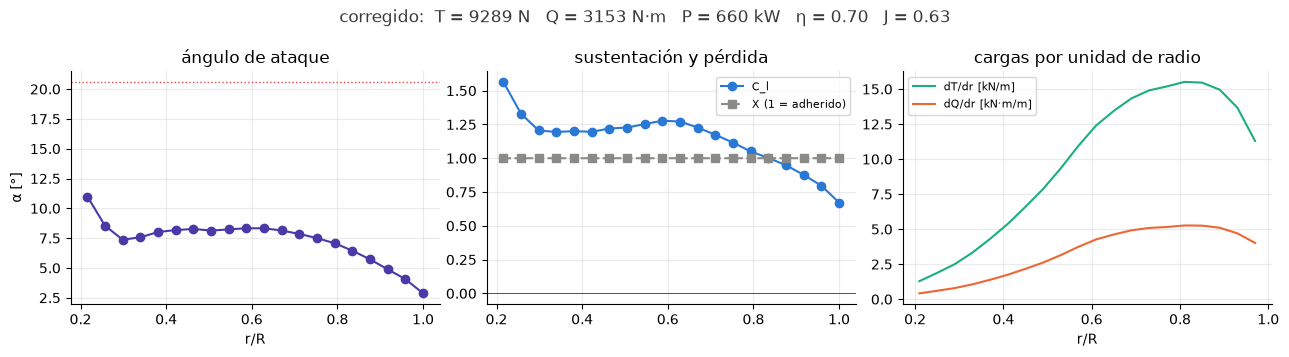

In [20]:
def widget_pala(beta=32.0, V=50.0, rpm=2000.0, h=0.0, version="corregido"):
    rho, mu = isa(h)[2:]; Om = rpm*2*math.pi/60
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
    if version == "corregido":
        d = traub(Om, V, beta, rho, mu, detalle=True); r = r_p
        T, Q = d["T"], d["Q"]
        axs[2].plot(r/R_P, d["dT"]/1e3, color=COL["helice"], label="dT/dr [kN/m]")
        axs[2].plot(r/R_P, d["dQ"]/1e3, color=COL["pt"], label="dQ/dr [kN·m/m]")
    else:
        d = traub_entrega(Om, V, beta, rho, mu); r = d["r"]
        T, Q = d["T"], d["Q"]
        axs[2].text(0.5, 0.5, "la entrega ajusta una recta\na los integrandos:\nno hay distribución radial", ha="center",
                    transform=axs[2].transAxes, color=COL["entrega"])
    axs[0].plot(r/r.max(), np.degrees(d["al"]), "o-", color=COL["gg"], label="α")
    axs[0].axhline(20.6 if version == "corregido" else 5, color=COL["aviso"], ls=":", lw=1)
    axs[0].set_xlabel("r/R"); axs[0].set_ylabel("α [°]"); axs[0].set_title("ángulo de ataque")
    axs[1].plot(r/r.max(), d["cl"], "o-", color=COL["aire"], label="C_l"); axs[1].plot(r/r.max(), d["X"], "s--", color=COL["gris"], label="X (1 = adherido)")
    axs[1].axhline(0, color=COL["tinta"], lw=0.6); axs[1].legend(fontsize=8); axs[1].set_title("sustentación y pérdida")
    axs[2].legend(fontsize=8); axs[2].set_xlabel("r/R"); axs[2].set_title("cargas por unidad de radio")
    P = Q*Om
    eta = V*T/P if P > 0 else float("nan")
    fig.suptitle("%s:  T = %.0f N   Q = %.0f N·m   P = %.0f kW   η = %.2f   J = %.2f" %
                 (version, T, Q, P/1e3, eta, V/(rpm/60*2*R_P)), color=COL["entrega"] if version != "corregido" else COL["tinta"])
    plt.tight_layout(); plt.show()
w5 = dict(beta=FloatSlider(value=32, min=10, max=60, step=0.5, description="β (r/R=0.638) [°]"),
          V=FloatSlider(value=50, min=0, max=160, step=2, description="V [m/s]"),
          rpm=FloatSlider(value=2000, min=1200, max=2200, step=20, description="rpm hélice"),
          h=FloatSlider(value=0, min=0, max=7600, step=200, description="h [m]"),
          version=ToggleButtons(options=["corregido", "entrega"], description="modelo"))
display(VBox([HBox([w5["beta"], w5["V"], w5["rpm"]]), HBox([w5["h"], w5["version"]]), interactive_output(widget_pala, w5)]))

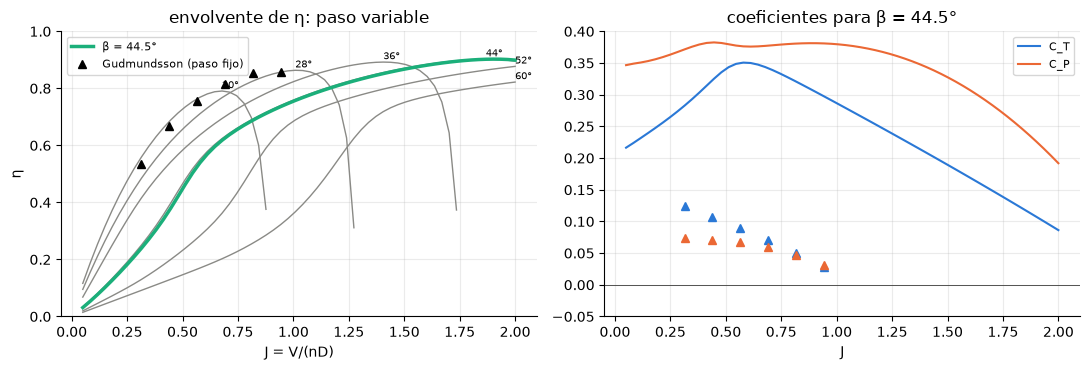

In [21]:
# Widget 6: mapa de la hélice (C_T, C_P, η contra J) para una familia de pasos
GUD = np.array([[0.3142, 0.1250, 0.0734, 0.535], [0.4398, 0.1077, 0.0710, 0.667], [0.5655, 0.0898, 0.0674, 0.754],
                [0.6912, 0.0703, 0.0596, 0.815], [0.8168, 0.0497, 0.0475, 0.854], [0.9425, 0.0278, 0.0306, 0.856]])
def mapa_helice(betas, rpm=2000.0, h=0.0):
    rho, mu = isa(h)[2:]; n = rpm/60; Om = 2*math.pi*n; D2 = 2*R_P
    out = {}
    for b in betas:
        J = np.linspace(0.05, 2.0, 60); CT, CP = [], []
        for j in J:
            T, Q = traub(Om, j*n*D2, b, rho, mu); CT.append(T/(rho*n**2*D2**4)); CP.append(Q*Om/(rho*n**3*D2**5))
        CT, CP = np.array(CT), np.array(CP)
        eta = np.where((CT > 0) & (CP > 0), J*CT/np.maximum(CP, 1e-9), np.nan)
        out[b] = (J, CT, CP, eta)
    return out
def widget_mapa_helice(beta_sel=44.5, rpm=2000.0, h=3800.0):
    betas = [20, 28, 36, 44, 52, 60]
    M_ = mapa_helice(betas + [beta_sel], rpm, h)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    for b in betas:
        J, CT, CP, eta = M_[b]
        a1.plot(J, eta, color=COL["gris"], lw=1); a1.text(J[np.nanargmax(eta)], np.nanmax(eta) + 0.01, "%d°" % b, fontsize=7)
    J, CT, CP, eta = M_[beta_sel]
    a1.plot(J, eta, color=COL["helice"], lw=2.5, label="β = %.1f°" % beta_sel)
    a1.plot(GUD[:, 0], GUD[:, 3], "k^", label="Gudmundsson (paso fijo)")
    a1.set_ylim(0, 1); a1.set_xlabel("J = V/(nD)"); a1.set_ylabel("η"); a1.legend(fontsize=8); a1.set_title("envolvente de η: paso variable")
    a2.plot(J, CT, color=COL["aire"], label="C_T"); a2.plot(J, CP, color=COL["pt"], label="C_P")
    a2.plot(GUD[:, 0], GUD[:, 1], "^", color=COL["aire"]); a2.plot(GUD[:, 0], GUD[:, 2], "^", color=COL["pt"])
    a2.axhline(0, color=COL["tinta"], lw=0.6); a2.set_xlabel("J"); a2.legend(fontsize=8); a2.set_ylim(-0.05, 0.4)
    a2.set_title("coeficientes para β = %.1f°" % beta_sel)
    plt.tight_layout(); plt.show()
w6 = dict(beta_sel=FloatSlider(value=44.5, min=15, max=65, step=0.5, description="β [°]"),
          rpm=FloatSlider(value=2000, min=1500, max=2200, step=50, description="rpm"),
          h=FloatSlider(value=3800, min=0, max=7600, step=200, description="h [m]"))
display(VBox([HBox(list(w6.values())), interactive_output(widget_mapa_helice, w6)]))

## 8. El motor ensamblado

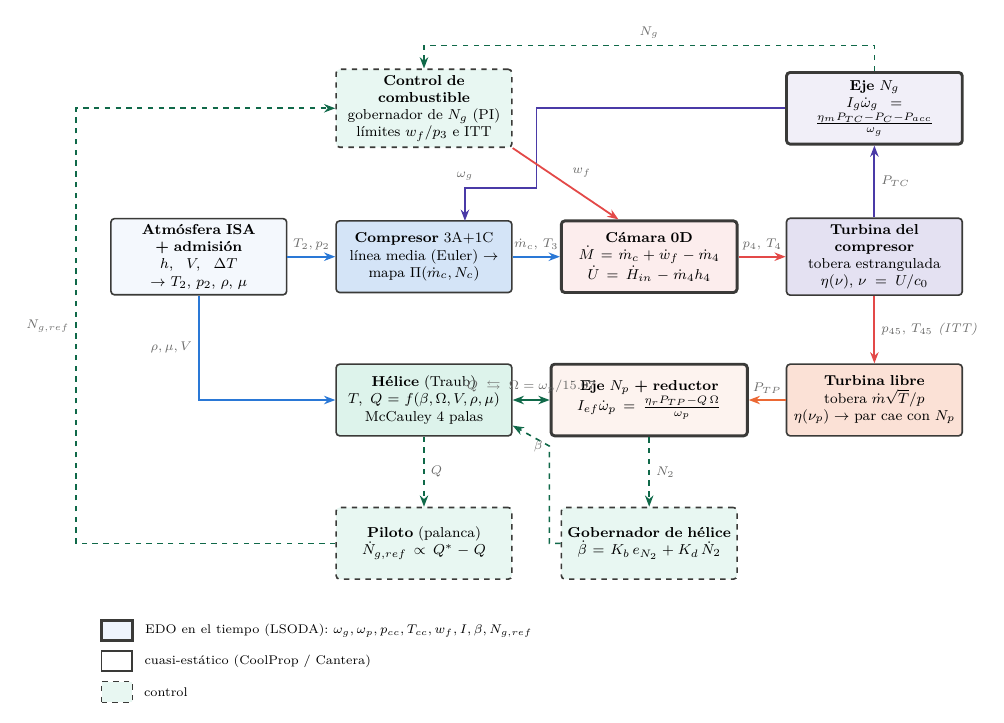

*Figura 3 (TikZ).* Bloques cuasi-estáticos: atmósfera, mapa del compresor, toberas y turbinas, hélice. Bloques con EDO en el tiempo: los dos ejes, la cámara, el actuador de combustible, el paso y el "piloto". En total son **8 EDO**:

$$\mathbf y=[\omega_g,\ \omega_p,\ p_{cc},\ T_{cc},\ w_f,\ I_{N_g},\ \beta,\ N_{g,ref}]$$

$$I_g\,\dot\omega_g=\frac{\eta_mP_{TC}-P_C-P_{acc}}{\omega_g},\qquad \Big(I_{TP}+\frac{I_{hel}}{G^2}\Big)\dot\omega_p=\frac{\eta_{red}P_{TP}-Q\,\Omega}{\omega_p},\qquad \Omega=\frac{\omega_p}{G},\ G=15.07$$

Con $I_g=0.12$ y $I_{TP}=0.06$ kg·m² (SolidWorks, tesis de 2019). SUPUESTO: $I_{hel}=8$ kg·m². La presión entre turbinas $p_{45}$ se resuelve de forma algebraica, igualando el caudal de las dos toberas, porque ese volumen es pequeño.

In [22]:
# === Motor completo: álgebra cuasi-estática + 8 EDO + controles ===
# Las no linealidades del control (topes, saturaciones) se suavizan con tanh: los saltos colapsan el paso de LSODA.
NX = 8   # [w_gg, w_pt, p_cc, T_cc, wf, I_ng, beta, Ng_ref(par)]
CTRL = dict(Kp=2.0, Ki=1.5, tau_f=0.10, R_acc=1.35, R_dec=0.30, K_itt=0.02,
            Kb=120.0, Kd=25.0, beta_min=10.0, beta_max=84.5, rate_b=15.0, Kq=0.15, T_aw=0.3,
            Ng_idle=0.52*NG100)

def termo_motor(Ng, Npt, pcc, Tcc, wf, amb, comb):
    """Algebra del generador de gas y turbinas (cuasi-estatico excepto la camara)."""
    T2, p2 = amb["T0"], amb["p0"]
    th, de = T2/288.15, p2/101325.0
    Nfr = Ng/NG100/math.sqrt(th)
    mc_c, wc_c, eta_c, bombeo = mapa_compresor(Nfr, pcc/p2)
    mc = mc_c*de/math.sqrt(th); w = wc_c*th
    T3 = float(AIRE.Th(AIRE.hT(T2) + w))
    f = float(np.clip(wf/max(mc, 1e-3), 0.0, 0.06))
    G = gas(comb, f)
    dp = D["dp_cc"]*((mc*math.sqrt(T3)/pcc)/(D["m"]*math.sqrt(D["T3"])/D["p3"]))**2
    p4 = pcc*(1 - min(dp, 0.2))
    pa = amb["p"]
    def red(p45):
        p45 = min(p45, p4*0.99999)
        m4 = D["K4"]*p4/math.sqrt(Tcc)*flujo_tobera(p45/p4)
        dhs = float(G.hT(Tcc) - G.hT(G.T_isen(Tcc, p45/p4)))
        nu = (2*math.pi*Ng/60*R_CT)/math.sqrt(2*max(dhs, 1.0))
        et = eta_turbina(nu, D["nu_ct"], D["eta_T"])
        T45 = float(G.Th(G.hT(Tcc) - et*dhs))
        p6 = pa + D["kx"]*m4**2*T45/pa
        m45 = D["K45"]*p45/math.sqrt(T45)*flujo_tobera(p6/p45)
        return m4 - m45, m4, T45, p6, et
    lo = pa*1.0001
    if p4 <= lo*1.0001 or red(lo)[0] < 0:            # sin caudal posible (motor parado)
        p45 = min(lo, p4*0.99999)
    else:
        p45 = brentq(lambda x: red(x)[0], lo, p4*0.99999, xtol=1e-4)
    _, m4, T45, p6, eta_ct = red(p45)
    P_ct = m4*float(G.hT(Tcc) - G.hT(T45))
    dhs_pt = float(G.hT(T45) - G.hT(G.T_isen(T45, min(p6/p45, 1.0)))) if p45 > p6 else 0.0
    nu_p = (2*math.pi*Npt/60*R_PT)/math.sqrt(2*max(dhs_pt, 1.0))
    eta_pt = eta_turbina(nu_p, D["nu_pt"], D["eta_T"])
    P_pt = m4*eta_pt*dhs_pt
    T6 = float(G.Th(G.hT(T45) - eta_pt*dhs_pt))
    return dict(mc=mc, w=w, T3=T3, p3=pcc, eta_c=eta_c, bombeo=bool(bombeo), f=f, G=G, p4=p4, m4=m4,
                p45=p45, T45=T45, p6=p6, T6=T6, P_ct=P_ct, P_pt=P_pt, eta_ct=eta_ct, eta_pt=eta_pt,
                W_c=mc*w, Nfr=Nfr)

def sig(x):
    return 0.5*(1.0 + math.tanh(x))

def smin(a, b, eps):
    return 0.5*(a + b - math.sqrt((a - b)**2 + eps**2))

def smax(a, b, eps):
    return 0.5*(a + b + math.sqrt((a - b)**2 + eps**2))

def rhs(t, y, perfil, comb, salida=False):
    wg, wp, pcc, Tcc, wf, Ing, beta, Ngp = y
    wg, wp = max(wg, 50.0), max(wp, 20.0)
    u = perfil(t)
    T0, p0, Ta, pa, rho, mu = admision(u["h"], u["V"], u.get("dT", 0.0))
    amb = dict(T0=T0, p0=p0, T=Ta, p=pa, rho=rho, mu=mu)
    Ng, Npt = wg*60/(2*math.pi), wp*60/(2*math.pi)
    e = termo_motor(Ng, Npt, pcc, Tcc, wf, amb, comb)
    G = e["G"]
    # --- eje del generador de gas
    P_acc = D["P_acc"]*(Ng/NG100)**2
    dwg = (ETA_M*e["P_ct"] - e["W_c"] - P_acc)/(I_GG*wg)
    # --- eje de potencia + reductor + helice (Traub)
    Om = wp/G_RED
    Th_, Qh = traub(Om, u["V"], beta, rho, mu)
    I_ef = I_PT + I_HEL/G_RED**2
    dwp = (ETA_RED*e["P_pt"] - Qh*Om)/(I_ef*wp)
    # --- camara de combustion (volumen de control 0D)
    R = G.R; M = pcc*V_CC/(R*Tcc)
    h_in = e["mc"]*(AIRE.hT(e["T3"]) + DH_REF) + wf*comb["hf"]
    hb = float(G.hT(Tcc)); cpb = float(G.cpT(Tcc)); cvb = cpb - R; ub = hb - R*Tcc
    dM = e["mc"] + wf - e["m4"]
    dT = (h_in - e["m4"]*hb - ub*dM)/(M*cvb)
    dp = R/V_CC*(Tcc*dM + M*dT)
    # --- control de combustible (gobernador de Ng + limites)
    modo_par = "Q" in u
    Ng_ref = smin(Ngp if modo_par else u["Ng"], TCDS["Ng_max"] - 200.0, 100.0)
    err = (Ng_ref - Ng)/NG100
    wf_cmd = Ing + CTRL["Kp"]*D["mf"]*err
    lim_hi = CTRL["R_acc"]*D["wf_pb"]*pcc*(Ng/NG100)**0.5
    lim_lo = CTRL["R_dec"]*D["wf_pb"]*pcc
    ITT = e["T45"] - 273.15
    # limitador de ITT: minimo suave (evita discontinuidades que colapsan el paso del integrador)
    lim_hi = smin(lim_hi, wf*(1 - CTRL["K_itt"]*(ITT - TCDS["ITT_max"])), 0.02*D["mf"])
    if "wf" in u:                      # combustible en lazo abierto (como la entrega)
        wf_cmd, lim_lo, lim_hi = u["wf"], -1.0, 1.0
    wf_c = smin(smax(wf_cmd, lim_lo, 0.01*D["mf"]), lim_hi, 0.01*D["mf"])
    dI = CTRL["Ki"]*D["mf"]*err + (wf_c - wf_cmd)/CTRL["T_aw"]    # antiwindup por retro-calculo
    dwf = (wf_c - wf)/CTRL["tau_f"]
    # --- gobernador de helice (paso): tasa saturada suave y topes suaves
    N2 = Om*60/(2*math.pi)
    db = CTRL["Kb"]*(N2 - u["N2"])/u["N2"] + CTRL["Kd"]*(dwp/G_RED*60/(2*math.pi))/u["N2"]
    db = CTRL["rate_b"]*math.tanh(db/CTRL["rate_b"])
    db *= sig((beta - CTRL["beta_min"])/0.3) if db < 0 else sig((CTRL["beta_max"] - beta)/0.3)
    # --- "piloto": ajusta Ng_ref para sostener el par en el eje de la helice
    dNgp = 0.0
    if modo_par:
        dNgp = CTRL["Kq"]*NG100*(u["Q"] - Qh)/TCDS["Q_max"]
        dNgp *= sig((Ngp - CTRL["Ng_idle"])/150.0) if dNgp < 0 else sig((TCDS["Ng_max"] - 350.0 - Ngp)/120.0)
    dy = [dwg, dwp, dp, dT, dwf, dI, db, dNgp]
    if salida:
        P_eje = Qh*Om
        return dict(t=t, Ng=Ng, Ng_pct=100*Ng/NG100, Npt=Npt, N2=N2, beta=beta, Q=Qh, T=Th_, P=P_eje,
                    wf=wf, ITT=ITT, T3=e["T3"], p3=pcc, T4=Tcc, p4=e["p4"], T5=e["T45"], p5=e["p45"],
                    T6=e["T6"], p6=e["p6"], mc=e["mc"], f=e["f"], eta_c=e["eta_c"], bombeo=e["bombeo"],
                    SFC=wf*3600/max(P_eje/1e3, 1.0), eta_th=P_eje/max(wf*comb["LHV"], 1.0),
                    eta_p=u["V"]*Th_/max(P_eje, 1.0), h=u["h"], V=u["V"], T2=T0, p2=p0)
    return dy

def y_diseno():
    return [NG100*2*math.pi/60, TCDS["Npt"]*2*math.pi/60, D["p3"], D["T4"], D["mf"], D["mf"], 30.0, NG100]

from scipy.optimize import root
_Z_PREV = {}
def estacionario(Ng, N2, h=0.0, V=0.0, comb=None, dT=0.0, z0=None):
    """Punto estacionario con Ng y N2 impuestos.
    1) generador de gas: (p_cc, T_cc, wf) tales que dw_gg = dp = dT = 0;
    2) paso de helice beta tal que Q_helice = potencia de la turbina libre."""
    comb = comb or D["comb"]
    perfil = lambda t: dict(h=h, V=V, dT=dT, Ng=Ng, N2=N2)
    wg, wp = Ng*2*math.pi/60, N2*G_RED*2*math.pi/60
    esc = np.array([D["p3"], D["T4"], D["mf"]])
    def res(z):
        pcc, Tcc, wf = z*esc
        dy = rhs(0, [wg, wp, pcc, Tcc, wf, wf, 40.0, Ng], perfil, comb)
        return [dy[0]/wg*1e2, dy[2]/D["p3"], dy[3]/D["T4"]]
    if z0 is None:
        # continuacion en velocidad corregida, partiendo de la semejanza (theta, delta)
        T0, p0 = admision(h, V, dT)[:2]
        th, de = T0/288.15, p0/D["p2"]
        fr = Ng/NG100/math.sqrt(th)
        z = np.array([de, th, de*math.sqrt(th)])
        pasos = np.linspace(1.0, fr, max(2, int(abs(1 - fr)/0.025) + 2))
        for nf in pasos:
            Ngi = nf*NG100*math.sqrt(th); wgi = Ngi*2*math.pi/60
            def ri(zz, Ngi=Ngi, wgi=wgi):
                pcc, Tcc, wf = zz*esc
                pf = lambda t: dict(h=h, V=V, dT=dT, Ng=Ngi, N2=N2)
                dy = rhs(0, [wgi, wp, pcc, Tcc, wf, wf, 40.0, Ngi], pf, comb)
                return [dy[0]/wgi*1e2, dy[2]/D["p3"], dy[3]/D["T4"]]
            z = root(ri, z, method="hybr").x
        z0 = z
    s = root(res, z0, method="hybr")
    pcc, Tcc, wf = s.x*esc
    T0, p0, Ta, pa, rho, mu = admision(h, V, dT)
    e = termo_motor(Ng, N2*G_RED, pcc, Tcc, wf, dict(T0=T0, p0=p0, T=Ta, p=pa, rho=rho, mu=mu), comb)
    Om = N2*2*math.pi/60; Pn = ETA_RED*e["P_pt"]
    fq = lambda b: traub(Om, V, b, rho, mu)[1]*Om - Pn
    # primera raiz en paso creciente (rama sin perdida): el par de la helice no es monotono en perdida profunda
    bs = np.arange(-10.0, 84.0, 2.0); fs = [fq(b) for b in bs]
    beta = float("nan")
    for k in range(len(bs) - 1):
        if fs[k] <= 0 < fs[k + 1]:
            beta = brentq(fq, bs[k], bs[k + 1]); break
    out = rhs(0, [wg, wp, pcc, Tcc, wf, wf, beta if beta == beta else CTRL["beta_min"], Ng], perfil, comb, salida=True)
    if beta != beta:
        out["beta"] = float("nan")
    out["resid"] = float(np.max(np.abs(s.fun))); out["z"] = s.x
    return out

def simular(perfil, t_fin, y0=None, comb=None, n=400, max_step=0.5):
    comb = comb or D["comb"]
    y0 = y0 if y0 is not None else y_diseno()
    sol = solve_ivp(lambda t, y: rhs(t, y, perfil, comb), [0, t_fin], y0, method="LSODA",
                    t_eval=np.linspace(0, t_fin, n), max_step=max_step, rtol=1e-5, atol=1e-6)
    filas = [rhs(t, sol.y[:, k], perfil, comb, salida=True) for k, t in enumerate(sol.t)]
    res = {k: np.array([f[k] for f in filas]) for k in filas[0]}
    res["ok"] = sol.success; res["msg"] = sol.message; res["y_fin"] = sol.y[:, -1]
    return res

In [23]:
# === Escenarios (misiones, ensayos) y caché de resultados ===
def tramo(t, pts):
    return float(np.interp(t, [p[0] for p in pts], [p[1] for p in pts]))

def mision(version="corregida"):
    if version == "entrega":     # como la entrega 2024: desde 0 m, V <= 50 m/s, par por fases (torque_function)
        H = [(0, 0.0), (60, 0.0), (180, 3800.0), (420, 3800.0), (570, 0.0), (600, 0.0)]
        V = [(0, 2.0), (60, 2.0), (180, 50.0), (420, 50.0), (570, 2.0), (600, 2.0)]
        Q = [(0, 2000), (60, 2000), (61, 3000), (170, 3000), (171, 2000), (570, 2000), (571, 1000), (580, 1000), (581, 500), (600, 500)]
    else:                        # corregida: El Dorado (2548 m) -> Guaymaral (2560 m), velocidades del Cheyenne
        H = [(0, 2548.0), (110, 2548.0), (180, 3300.0), (220, 3800.0), (420, 3800.0), (560, 2560.0), (600, 2560.0)]
        V = [(0, 3), (60, 3), (70, 10), (110, 55), (180, 75), (200, 110), (420, 110), (450, 85), (560, 55), (575, 20), (600, 5)]
        Q = [(0, 700), (60, 700), (62, 3023), (180, 3023), (182, 2563), (220, 2563), (222, 2000), (420, 2000),
             (422, 900), (560, 900), (562, 600), (575, 600), (577, 400), (600, 400)]
    return lambda t: dict(h=tramo(t, H), V=tramo(t, V), Q=tramo(t, Q), N2=2000.0, Ng=NG100)

def y_inicial(Ng, N2=2000.0, h=0.0, V=0.0, comb=None):
    o = estacionario(Ng, N2, h=h, V=V, comb=comb)
    b = o["beta"] if o["beta"] == o["beta"] else CTRL["beta_min"] + 1.0
    return [Ng*2*math.pi/60, N2*G_RED*2*math.pi/60, o["p3"], o["T4"], o["wf"], o["wf"], b, Ng]

def ensayo_combustible(x_jet, lazo="cerrado"):
    # banco en tierra (nivel del mar): ralenti de vuelo -> despegue
    cb = combustible(x_jet)
    Qp = [(0, 900), (10, 900), (40, 3023), (90, 3023)]
    def perfil(t):
        u = dict(h=0.0, V=0.0, N2=2000.0, Ng=NG100)
        if lazo == "cerrado":
            u["Q"] = tramo(t, Qp)
        else:       # programa de combustible fijo de la entrega (PARAMETRIZACIONFINAL.m), escalado al diseno
            u["wf"] = tramo(t, [(0, 0.035), (10, 0.035), (40, D["mf"]), (90, D["mf"])])
        return u
    return perfil, cb

CACHE = {}
RUTA_CACHE = os.path.join("data", "pt6_resultados.json")
def _a_json(r):
    return {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in r.items() if k not in ("y_fin",)}
def correr(clave, fn, forzar=False):
    if not forzar and clave in CACHE:
        return CACHE[clave]
    r = fn(); r = {k: (np.array(v) if isinstance(v, list) else v) for k, v in _a_json(r).items()}
    CACHE[clave] = r
    try:
        json.dump({k: _a_json(v) for k, v in CACHE.items()}, open(RUTA_CACHE, "w"))
    except Exception as e:
        print("no se pudo guardar la caché:", e)
    return r
def cargar_cache():
    if os.path.exists(RUTA_CACHE):
        for k, v in json.load(open(RUTA_CACHE)).items():
            CACHE[k] = {kk: (np.array(vv) if isinstance(vv, list) else vv) for kk, vv in v.items()}
    return list(CACHE)

caché: ['mision_corregida', 'mision_entrega', 'comb_1.00_abierto', 'comb_1.00_cerrado', 'comb_0.75_abierto', 'comb_0.75_cerrado', 'comb_0.50_abierto', 'comb_0.50_cerrado']


,estación,T carta [°C],T modelo [°C],error T [K],p carta [kPa],p modelo [kPa],error p [%],uso
0,2,24,15.00,-9.00,92.39,100.31,8.57,entrada ISA (la carta da 24 °C y 92 kPa)
1,3,316,316.02,0.02,770.14,770.05,-0.01,calibrado
2,4,1070,1070.00,0.00,753.60,753.51,-0.01,calibrado (llama)
3,5,738,738.05,0.05,284.06,264.84,-6.77,"T calibrada, p predicha"
4,6,608,581.47,-26.53,124.80,124.79,-0.00,T predicha (p impuesta)


Potencia en la hélice 633.9 kW (TCDS 634)   par 3027 N·m   paso 32.3°   SFC 0.372 kg/(kW·h) = 0.611 lb/(shp·h)
Residuo del punto estacionario: 1.1e-03


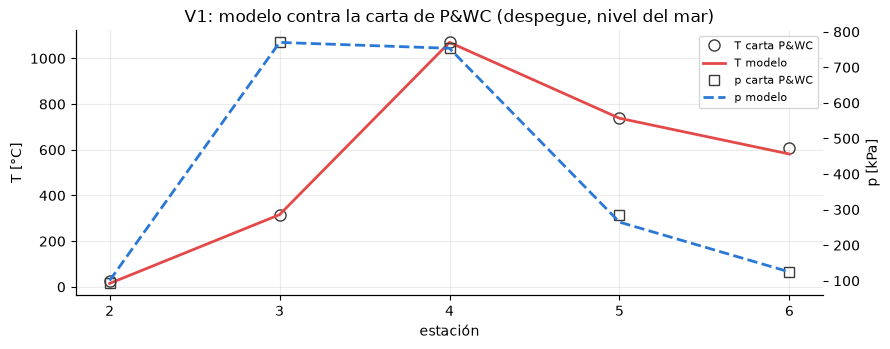

In [24]:
print("caché:", cargar_cache())
# V1: punto de diseño recalculado por el modelo dinámico (todas las EDO en cero) contra la carta de P&WC
o = estacionario(NG100, 2000.0)
mod = {"2": (o["T2"] - 273.15, o["p2"]), "3": (o["T3"] - 273.15, o["p3"]), "4": (D["T4core"] - 273.15, o["p4"]),
       "5": (o["T5"] - 273.15, o["p5"]), "6": (o["T6"] - 273.15, o["p6"])}
filas = []
for k, (Tm, pm) in mod.items():
    Tc, pc = CARTA[k]
    filas.append({"estación": k, "T carta [°C]": Tc, "T modelo [°C]": Tm, "error T [K]": Tm - Tc,
                  "p carta [kPa]": pc*PSI/1e3, "p modelo [kPa]": pm/1e3, "error p [%]": 100*(pm/(pc*PSI) - 1),
                  "uso": {"2": "entrada ISA (la carta da 24 °C y 92 kPa)", "3": "calibrado", "4": "calibrado (llama)", "5": "T calibrada, p predicha",
                         "6": "T predicha (p impuesta)"}[k]})
V1 = pd.DataFrame(filas); display(V1.round(2))
print("Potencia en la hélice %.1f kW (TCDS 634)   par %.0f N·m   paso %.1f°   SFC %.3f kg/(kW·h) = %.3f lb/(shp·h)"
      % (o["P"]/1e3, o["Q"], o["beta"], o["SFC"], o["SFC"]*2.2046*0.7457))
print("Residuo del punto estacionario: %.1e" % o["resid"])
fig, ax = plt.subplots(figsize=(9, 3.6)); ax2 = ax.twinx(); ax2.grid(False)
ks = ["2", "3", "4", "5", "6"]
ax.plot(ks, [CARTA[k][0] for k in ks], "o", color=COL["medido"], ms=8, mfc="none", label="T carta P&WC")
ax.plot(ks, [mod[k][0] for k in ks], "-", color=COL["gas"], lw=2, label="T modelo")
ax2.plot(ks, [CARTA[k][1]*PSI/1e3 for k in ks], "s", color=COL["medido"], ms=7, mfc="none", label="p carta P&WC")
ax2.plot(ks, [mod[k][1]/1e3 for k in ks], "--", color=COL["aire"], lw=2, label="p modelo")
ax.set_ylabel("T [°C]"); ax2.set_ylabel("p [kPa]"); ax.set_xlabel("estación")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8)
ax.set_title("V1: modelo contra la carta de P&WC (despegue, nivel del mar)"); plt.tight_layout(); plt.show()

**V2: la potencia plana (*flat rating*).** El TCDS garantiza 634 kW hasta 46 °C de ambiente a nivel del mar. Con el modelo se busca la temperatura a la que entregar 634 kW exige llegar a la ITT máxima (800 °C) o a $N_g$ máximo. Es una **predicción**: ningún dato de temperatura ambiente entró en la calibración.

In [25]:
def ng_para(P_obj, dT=0.0, h=0.0, V=0.0, comb=None):
    return brentq(lambda g: estacionario(g*NG100, 2000.0, h=h, V=V, dT=dT, comb=comb)["P"] - P_obj, 0.85, 1.10, xtol=2e-4)
filas = []
for dT in [0, 10, 20, 25, 31]:
    g = ng_para(634e3, dT); o = estacionario(g*NG100, 2000.0, dT=dT)
    filas.append((15 + dT, 100*g, o["ITT"], o["wf"]))
FR = pd.DataFrame(filas, columns=["T ambiente [°C]", "Ng [%]", "ITT [°C]", "w_f [kg/s]"]); display(FR.round(2))
T_lim = np.interp(TCDS["ITT_max"], FR["ITT [°C]"], FR["T ambiente [°C]"])
print("Predicción: 634 kW hasta %.1f °C (ITT = 800 °C).  TCDS: 46 °C.  Diferencia: %.1f K." % (T_lim, T_lim - 46))

,T ambiente [°C],Ng [%],ITT [°C],w_f [kg/s]
0,15,100.00,738.10,0.07
1,25,101.21,766.98,0.07
2,35,102.41,795.62,0.07
3,40,103.01,810.19,0.07
4,46,103.70,827.80,0.07


Predicción: 634 kW hasta 36.5 °C (ITT = 800 °C).  TCDS: 46 °C.  Diferencia: -9.5 K.


El modelo es **conservador**: alcanza el límite de ITT unos grados antes que el motor certificado. La pendiente $dITT/dT_{amb}\approx2.9$ es física. La diferencia indica que el PT6A-61 real tiene en el punto de la carta más margen de ITT que los 62 K de la carta (738 °C), o que gira por debajo del 100 % de $N_g$ (SUPUESTO de la calibración). El ejercicio 2 propone recalibrar con esa información.

**Widget 3: el mapa del compresor y la línea de operación.** El motor no opera en cualquier punto del mapa: el acople con la turbina fija una **línea de operación**. Elige la altitud y compara con el nivel del mar.

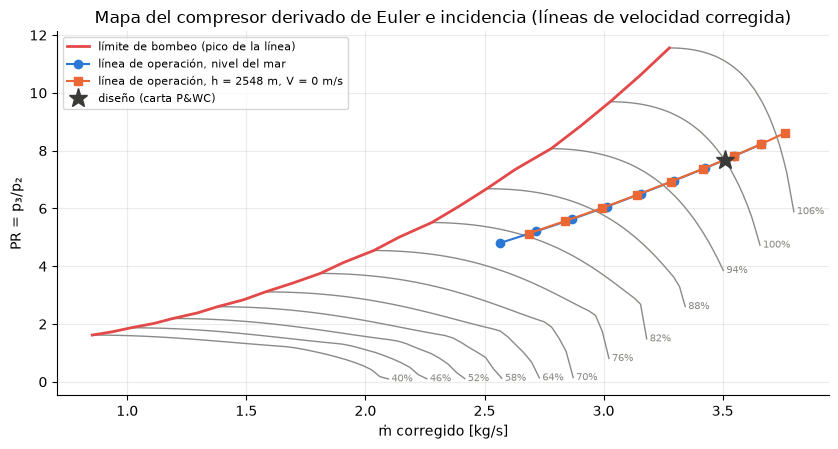

In [26]:
LINEAS = {}
def linea_operacion(h, V=0.0, dT=0.0):
    k = (h, V, dT)
    if k not in LINEAS:
        pts = []
        for g in np.linspace(0.80, 1.04, 9):
            o = estacionario(g*NG100, 2000.0, h=h, V=V, dT=dT)
            th, de = o["T2"]/288.15, o["p2"]/101325
            pts.append((o["mc"]*math.sqrt(th)/de, o["p3"]/o["p2"], 100*g, o["P"]/1e3, o["ITT"]))
        LINEAS[k] = np.array(pts)
    return LINEAS[k]
def widget_mapa(h=0.0, V=0.0):
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    for i, nf in enumerate(MAPA["Nfr"]):
        if i % 2: continue
        ax.plot(MAPA["m"][i], MAPA["PR"][i], color=COL["gris"], lw=1)
        ax.text(MAPA["m"][i][-1], MAPA["PR"][i][-1], " %.0f%%" % (100*nf), fontsize=7, color=COL["gris"], va="center")
    sg = np.array(MAPA["surge"]); ax.plot(sg[:, 0], sg[:, 1], color=COL["aviso"], lw=2, label="límite de bombeo (pico de la línea)")
    L0 = linea_operacion(0.0); ax.plot(L0[:, 0], L0[:, 1], "o-", color=COL["aire"], label="línea de operación, nivel del mar")
    if h > 0 or V > 0:
        L = linea_operacion(h, V); ax.plot(L[:, 0], L[:, 1], "s-", color=COL["pt"], label="línea de operación, h = %.0f m, V = %.0f m/s" % (h, V))
    ax.plot(D["m"]*math.sqrt(D["T2"]/288.15)/(D["p2"]/101325), D["p3"]/D["p2"], "*", color=COL["tinta"], ms=14, label="diseño (carta P&WC)")
    ax.set_xlabel("ṁ corregido [kg/s]"); ax.set_ylabel("PR = p₃/p₂"); ax.legend(fontsize=8, loc="upper left")
    ax.set_title("Mapa del compresor derivado de Euler e incidencia (líneas de velocidad corregida)")
    plt.tight_layout(); plt.show()
w3 = dict(h=Dropdown(options=[("nivel del mar", 0.0), ("Bogotá 2548 m", 2548.0), ("3800 m", 3800.0), ("7600 m", 7600.0)], value=2548.0, description="altitud"),
          V=FloatSlider(value=0, min=0, max=150, step=10, description="V [m/s]"))
display(VBox([HBox(list(w3.values())), interactive_output(widget_mapa, w3)]))

La línea de operación en altitud **casi coincide** con la del nivel del mar en variables corregidas: la turbina estrangulada impone la misma relación $\dot m\sqrt{T}/p$. Lo que cambia es la **velocidad corregida** que alcanza el motor ($N/\sqrt\theta$) y, con ella, la potencia.

## 9. Dinámica de los dos ejes y control: por qué el motor converge

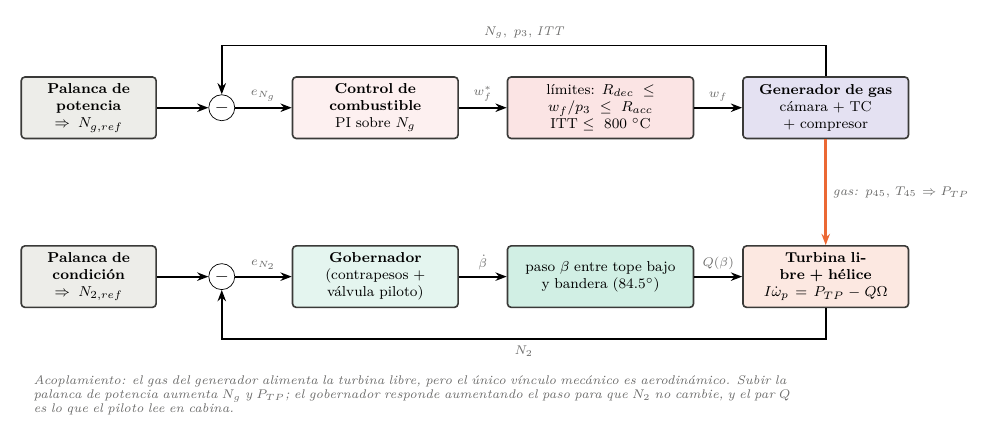

> **Corrección a la Lección 14.** Allí el par del compresor no dependía de $\omega$ (caudal fijo), y hubo que añadir un rozamiento cuadrático artificial $k_{wind}\omega^2$ para que el eje del generador de gas tuviera equilibrio. Con el cierre de la entrega, en el que el triángulo de entrada fija el caudal, ese término sobra: $\dot m\propto N$ y $w\propto U^2$, así que **la potencia del compresor crece como $N^3$** y su par como $N^2$. El equilibrio es estable por tres mecanismos físicos:

1. **Generador de gas:** al subir $N_g$, el compresor pide más potencia ($\propto N_g^3$) de la que el gas puede dar con el mismo combustible. El control de combustible cierra el lazo sobre $N_g$.
2. **Turbina libre:** su par cae con $N_p$ (§6). Si la hélice se acelera, recibe menos par.
3. **Hélice + gobernador:** el par aerodinámico crece con $\Omega^2$ y con $\beta$, y el gobernador mueve $\beta$ hasta que $N_2$ vuelve a la referencia.

**Widget 7: escalones de palanca.** Simulación en vivo (unos 5–10 s de cálculo). Mueve la palanca de potencia ($N_g$) y la de condición ($N_2$). Observa:
- La rapidez del eje del generador de gas, con constante de tiempo ~1 s.
- La sobrevelocidad transitoria de la hélice mientras el gobernador corrige el paso.
- El tope de paso bajo cuando la potencia no alcanza para sostener 2000 rpm.

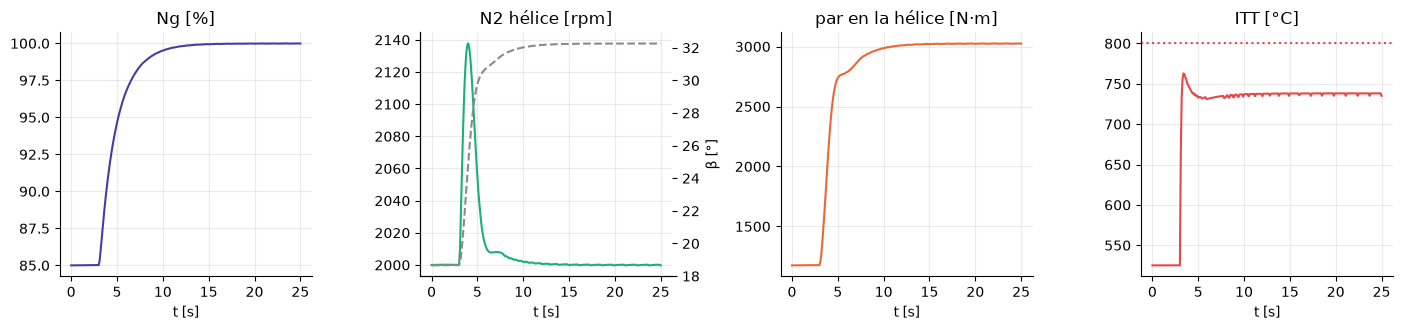

cálculo 10.3 s | constante de tiempo de Ng ≈ 2.00 s | máx. N2 = 2138 rpm | final: P = 633 kW, SFC = 0.370 kg/(kW·h)


In [27]:
out7 = Output()
w7 = dict(Ng0=FloatSlider(value=85, min=75, max=104, step=1, description="Ng inicial [%]"),
          Ng1=FloatSlider(value=100, min=75, max=104, step=1, description="Ng final [%]"),
          N2=FloatSlider(value=2000, min=1600, max=2200, step=50, description="N2 ref [rpm]"),
          h=FloatSlider(value=0, min=0, max=6000, step=500, description="h [m]"),
          V=FloatSlider(value=0, min=0, max=140, step=10, description="V [m/s]"))
b7 = Button(description="Simular escalón (25 s)", button_style="primary")
def correr_escalon(_=None, mostrar=True):
    p = {k: w.value for k, w in w7.items()}
    y0 = y_inicial(p["Ng0"]/100*NG100, 2000.0, h=p["h"], V=p["V"])
    perfil = lambda t: dict(h=p["h"], V=p["V"], Ng=(p["Ng0"] if t < 3 else p["Ng1"])/100*NG100, N2=(2000.0 if t < 3 else p["N2"]))
    t0 = time.time(); r = simular(perfil, 25.0, y0=y0, n=251, max_step=0.2)
    with out7:
        out7.clear_output(wait=True)
        fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))
        axs[0].plot(r["t"], r["Ng_pct"], color=COL["gg"]); axs[0].set_title("Ng [%]")
        axs[1].plot(r["t"], r["N2"], color=COL["helice"]); axs[1].set_title("N2 hélice [rpm]")
        a1b = axs[1].twinx(); a1b.plot(r["t"], r["beta"], "--", color=COL["gris"]); a1b.set_ylabel("β [°]"); a1b.grid(False)
        axs[2].plot(r["t"], r["Q"], color=COL["pt"]); axs[2].set_title("par en la hélice [N·m]")
        axs[3].plot(r["t"], r["ITT"], color=COL["gas"]); axs[3].axhline(800, color=COL["aviso"], ls=":"); axs[3].set_title("ITT [°C]")
        for a in axs: a.set_xlabel("t [s]")
        plt.tight_layout(); plt.show()
        i63 = np.argmax(np.abs(r["Ng_pct"] - r["Ng_pct"][0]) >= 0.632*abs(r["Ng_pct"][-1] - r["Ng_pct"][0]) - 1e-9)
        print("cálculo %.1f s | constante de tiempo de Ng ≈ %.2f s | máx. N2 = %.0f rpm | final: P = %.0f kW, SFC = %.3f kg/(kW·h)"
              % (time.time() - t0, r["t"][i63] - 3.0, r["N2"].max(), r["P"][-1]/1e3, r["SFC"][-1]))
b7.on_click(correr_escalon)
display(VBox([HBox([w7["Ng0"], w7["Ng1"], w7["N2"]]), HBox([w7["h"], w7["V"], b7]), out7]))
correr_escalon()

## 10. Banco de pruebas: indicadores del turbohélice

En el banco (nivel del mar, hélice a 2000 rpm, avión quieto) se barre la palanca de potencia y se registran los mismos indicadores que en el banco de motores de pistón de la Lección 12. La diferencia es el instrumento: aquí un **torquímetro** en el eje de la hélice, no un freno.

- **Potencia al eje** $P=Q\,\Omega$, medida con el torquímetro y el tacómetro de $N_2$.
- **Potencia nominal (certificada):** 634 kW. Es plana: está limitada por el par y la caja, no por la termodinámica.
- **Potencia máxima termodinámica:** la que da el núcleo en $N_g$ máx. o en ITT máx. Es mayor que la certificada al nivel del mar.
- **Consumo específico** $SFC=w_f/P$ y **eficiencia térmica** $\eta_{th}=P/(w_f\,\text{LHV})$.

,Ng [%],P eje [kW],par [N·m],w_f [kg/h],SFC [kg/(kW·h)],η térmica,ITT [°C],empuje estático [kN],paso [°]
0,80.0,143.401,684.691,101.986,0.711,0.117,466.932,5.205,12.920
1,84.0,223.775,1068.445,121.798,0.544,0.153,510.785,7.284,17.561
2,88.0,318.258,1519.568,147.402,0.463,0.180,565.115,9.260,21.848
3,92.0,424.284,2025.809,173.844,0.410,0.204,623.778,11.094,25.904
4,96.0,530.617,2533.512,205.339,0.387,0.216,682.112,12.500,29.382
5,100.0,633.884,3026.574,235.665,0.372,0.225,738.047,13.372,32.271
6,102.0,683.323,3262.628,251.187,0.368,0.227,764.762,13.593,33.470
7,104.0,731.744,3493.819,266.740,0.365,0.229,791.542,13.686,34.535


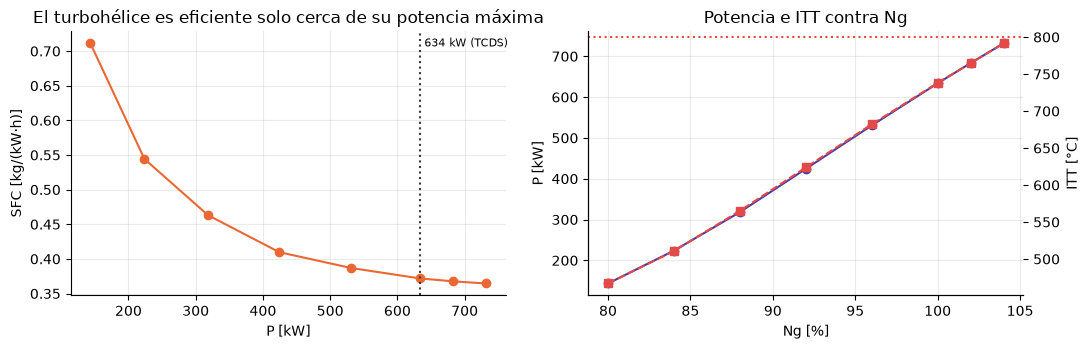

In [28]:
filas = []
for g in [0.80, 0.84, 0.88, 0.92, 0.96, 1.00, 1.02, 1.04]:
    o = estacionario(g*NG100, 2000.0)
    filas.append({"Ng [%]": 100*g, "P eje [kW]": o["P"]/1e3, "par [N·m]": o["Q"], "w_f [kg/h]": 3600*o["wf"],
                  "SFC [kg/(kW·h)]": o["SFC"], "η térmica": o["eta_th"], "ITT [°C]": o["ITT"], "empuje estático [kN]": o["T"]/1e3,
                  "paso [°]": o["beta"]})
    if not (o["beta"] == o["beta"]):
        filas[-1].update({"P eje [kW]": np.nan, "par [N·m]": np.nan, "SFC [kg/(kW·h)]": np.nan, "η térmica": np.nan,
                          "empuje estático [kN]": np.nan})
BANCO = pd.DataFrame(filas); display(BANCO.round(3))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(BANCO["P eje [kW]"], BANCO["SFC [kg/(kW·h)]"], "o-", color=COL["pt"]); a1.set_xlabel("P [kW]"); a1.set_ylabel("SFC [kg/(kW·h)]")
a1.axvline(634, color=COL["tinta"], ls=":"); a1.text(640, a1.get_ylim()[1]*0.97, "634 kW (TCDS)", fontsize=8)
a1.set_title("El turbohélice es eficiente solo cerca de su potencia máxima")
a2.plot(BANCO["Ng [%]"], BANCO["P eje [kW]"], "o-", color=COL["gg"], label="P"); a2b = a2.twinx(); a2b.grid(False)
a2b.plot(BANCO["Ng [%]"], BANCO["ITT [°C]"], "s--", color=COL["gas"], label="ITT"); a2b.axhline(800, color=COL["aviso"], ls=":")
a2.set_xlabel("Ng [%]"); a2.set_ylabel("P [kW]"); a2b.set_ylabel("ITT [°C]"); a2.set_title("Potencia e ITT contra Ng")
plt.tight_layout(); plt.show()

## 11. Tablero de cabina

**Widget 8: el PT6A-61 desde la cabina.** Las palancas son las de un Cheyenne IIIA:
- **potencia** → $N_g$;
- **condición** → rpm de la hélice;
- condiciones de vuelo: altitud, velocidad, desviación ISA y combustible.

Los relojes muestran el **estado estacionario** en el que convergen las 8 EDO, y los anunciadores marcan cada límite del TCDS. Si la potencia no alcanza para sostener las rpm pedidas, el paso queda en el **tope bajo** y la hélice gira más lento que la referencia (*underspeed*).

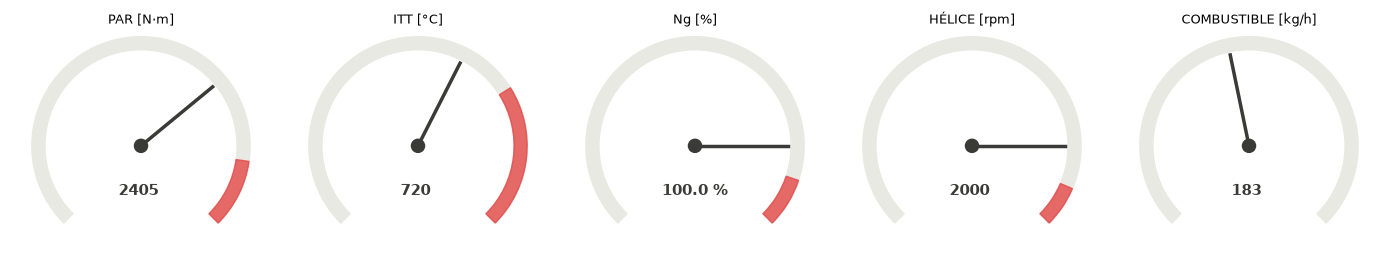

HTML(value="<div style='padding:6px;border-radius:4px;background:#1baf7a;color:white;font-weight:bold'>SIN ANU…

P eje = 504 kW | empuje = 10.45 kN | paso = 32.6° | SFC = 0.363 kg/(kW·h) | η térmica = 0.230 | η propulsiva = 0.00 | p3 = 595 kPa   (0.4 s)


In [29]:
def punto_cabina(Ng_pct, N2, h, V, dT, x_jet):
    cb = combustible(x_jet)
    Ng = Ng_pct/100*NG100
    o = estacionario(Ng, N2, h=h, V=V, dT=dT, comb=cb)
    modo = "gobernada"
    if not (o["beta"] == o["beta"]) or o["beta"] < CTRL["beta_min"]:
        # la turbina libre no puede sostener N2: paso en tope bajo y N2 libre
        T0, p0, Ta, pa, rho, mu = admision(h, V, dT); amb = dict(T0=T0, p0=p0, T=Ta, p=pa, rho=rho, mu=mu)
        pcc, Tcc, wf = o["z"]*np.array([D["p3"], D["T4"], D["mf"]])
        def bal(n2):
            e = termo_motor(Ng, n2*G_RED, pcc, Tcc, wf, amb, cb); Om = n2*2*math.pi/60
            return ETA_RED*e["P_pt"] - traub(Om, V, CTRL["beta_min"], rho, mu)[1]*Om
        try:
            n2 = brentq(bal, 200.0, N2)
            o = estacionario(Ng, n2, h=h, V=V, dT=dT, comb=cb); o["beta"] = CTRL["beta_min"]; modo = "tope bajo"
            o = rhs(0, [Ng*2*math.pi/60, n2*G_RED*2*math.pi/60, *list(o["z"]*np.array([D["p3"], D["T4"], D["mf"]])),
                        o["wf"], CTRL["beta_min"], Ng], lambda t: dict(h=h, V=V, dT=dT, Ng=Ng, N2=N2), cb, salida=True)
        except ValueError:
            modo = "sin solución"
    o["modo"] = modo
    return o

def reloj(ax, valor, vmin, vmax, rojo, titulo, unidad, fmt="%.0f"):
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.0, 1.25); ax.set_aspect("equal"); ax.axis("off")
    a0, a1 = 225, -45
    ang = lambda v: math.radians(a0 + (a1 - a0)*(min(max(v, vmin), vmax) - vmin)/(vmax - vmin))
    ax.add_patch(Wedge((0, 0), 1.0, a1, a0, width=0.12, color="#e9e9e4"))
    if rojo < vmax:
        ar = math.degrees(ang(rojo))
        ax.add_patch(Wedge((0, 0), 1.0, a1, ar, width=0.12, color=COL["aviso"], alpha=0.8))
    th = ang(valor)
    ax.plot([0, 0.85*math.cos(th)], [0, 0.85*math.sin(th)], color=COL["tinta"], lw=2.5)
    ax.add_patch(Circle((0, 0), 0.06, color=COL["tinta"]))
    c = COL["aviso"] if valor > rojo else COL["tinta"]
    ax.text(0, -0.45, (fmt % valor) + " " + unidad, ha="center", fontsize=11, fontweight="bold", color=c)
    ax.text(0, 1.12, titulo, ha="center", fontsize=9.5)

def widget_cabina(Ng_pct=100.0, N2=2000.0, h=2548.0, V=0.0, dT=0.0, combustible_sel=1.0):
    t0 = time.time()
    o = punto_cabina(Ng_pct, N2, h, V, dT, combustible_sel)
    fig, axs = plt.subplots(1, 5, figsize=(14, 3.2))
    reloj(axs[0], o["Q"], 0, 3500, 3023, "PAR [N·m]", "")
    reloj(axs[1], o["ITT"], 300, 1000, 800, "ITT [°C]", "")
    reloj(axs[2], o["Ng_pct"], 50, 110, 104.1, "Ng [%]", "%", "%.1f")
    reloj(axs[3], o["N2"], 0, 2400, 2205, "HÉLICE [rpm]", "")
    reloj(axs[4], 3600*o["wf"], 0, 400, 1e9, "COMBUSTIBLE [kg/h]", "")
    plt.tight_layout(); plt.show()
    avisos = []
    if o["ITT"] > TCDS["ITT_max"]: avisos.append("ITT > 800 °C")
    if o["Ng"] > TCDS["Ng_max"]: avisos.append("Ng > 39 000 rpm")
    if o["Q"] > TCDS["Q_max"] + 5: avisos.append("PAR > 3023 N·m")
    if o["modo"] != "gobernada": avisos.append("HÉLICE EN TOPE BAJO (N2 no gobernada)")
    if o["bombeo"]: avisos.append("BOMBEO")
    color = "#e34948" if avisos else "#1baf7a"
    display(HTML("<div style='padding:6px;border-radius:4px;background:%s;color:white;font-weight:bold'>%s</div>"
                 % (color, " | ".join(avisos) if avisos else "SIN ANUNCIADORES")))
    print("P eje = %.0f kW | empuje = %.2f kN | paso = %.1f° | SFC = %.3f kg/(kW·h) | η térmica = %.3f | η propulsiva = %.2f | p3 = %.0f kPa   (%.1f s)"
          % (o["P"]/1e3, o["T"]/1e3, o["beta"], o["SFC"], o["eta_th"], o["eta_p"], o["p3"]/1e3, time.time() - t0))
w8 = dict(Ng_pct=FloatSlider(value=100, min=78, max=104, step=0.5, description="potencia Ng [%]", continuous_update=False),
          N2=FloatSlider(value=2000, min=1600, max=2200, step=25, description="condición N2", continuous_update=False),
          h=FloatSlider(value=2548, min=0, max=7600, step=100, description="h [m]", continuous_update=False),
          V=FloatSlider(value=0, min=0, max=150, step=5, description="V [m/s]", continuous_update=False),
          dT=FloatSlider(value=0, min=-15, max=35, step=1, description="ΔT ISA [K]", continuous_update=False),
          combustible_sel=Dropdown(options=[("Jet A-1", 1.0), ("Jet 75 / bio 25", 0.75), ("Jet 50 / bio 50", 0.5)], value=1.0, description="combustible"))
display(VBox([HBox([w8["Ng_pct"], w8["N2"], w8["combustible_sel"]]), HBox([w8["h"], w8["V"], w8["dT"]]),
              interactive_output(widget_cabina, w8)]))

**Widget 9: la ruta El Dorado → Guaymaral.** Es la misión de la entrega de 2024, unos 600 s, simulada con las 8 EDO. El "piloto" sostiene el par de cada fase: rodaje, despegue (3023 N·m), ascenso (2563), crucero (2000), descenso y aterrizaje. Compara dos versiones:
- **como la entrega:** desde 0 m y con V ≤ 50 m/s;
- **corregida:** pista a 2548 m y velocidades de un Cheyenne IIIA.

Desliza el tiempo para leer la cabina en cada instante.

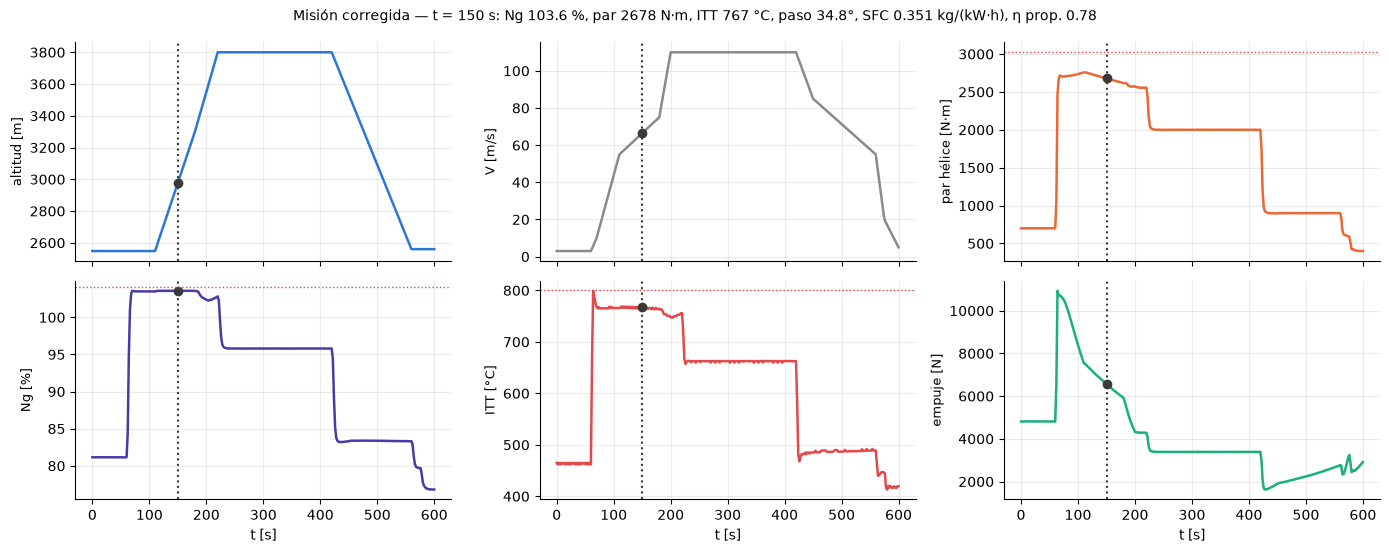

Despegue: par máximo alcanzado = 2760 N·m (objetivo 3023)  con Ng = 103.5 %  e ITT = 766 °C
Combustible consumido en la ruta: 22.7 kg


In [30]:
t0 = time.time()
for ver in ["corregida", "entrega"]:
    def _f(ver=ver):
        p0 = mision(ver)(0.0)
        # arranca en el equilibrio del rodaje: integra 30 s con el perfil congelado en t = 0
        y0 = y_inicial(0.81*NG100, 2000.0, h=p0["h"], V=p0["V"])
        y0 = list(simular(lambda t: mision(ver)(0.0), 30.0, y0=y0, n=11, max_step=0.5)["y_fin"])
        return simular(mision(ver), 600.0, y0=y0, n=301, max_step=0.5)
    correr("mision_" + ver, _f)
print("misiones listas (%.0f s)" % (time.time() - t0))
def widget_mision(version="corregida", t=200.0):
    r = CACHE["mision_" + version]; k = int(np.argmin(np.abs(r["t"] - t)))
    fig, axs = plt.subplots(2, 3, figsize=(14, 5.6), sharex=True)
    series = [("h", "altitud [m]", COL["aire"]), ("V", "V [m/s]", COL["gris"]), ("Q", "par hélice [N·m]", COL["pt"]),
              ("Ng_pct", "Ng [%]", COL["gg"]), ("ITT", "ITT [°C]", COL["gas"]), ("T", "empuje [N]", COL["helice"])]
    for a, (k2, lab, c) in zip(axs.flat, series):
        a.plot(r["t"], r[k2], color=c, lw=1.8); a.axvline(r["t"][k], color=COL["tinta"], ls=":"); a.set_ylabel(lab, fontsize=9)
        a.plot(r["t"][k], r[k2][k], "o", color=COL["tinta"])
    axs[0, 2].axhline(3023, color=COL["aviso"], ls=":", lw=1); axs[1, 0].axhline(104.1, color=COL["aviso"], ls=":", lw=1)
    axs[1, 1].axhline(800, color=COL["aviso"], ls=":", lw=1)
    for a in axs[1]: a.set_xlabel("t [s]")
    fig.suptitle("Misión %s — t = %.0f s: Ng %.1f %%, par %.0f N·m, ITT %.0f °C, paso %.1f°, SFC %.3f kg/(kW·h), η prop. %.2f"
                 % (version, r["t"][k], r["Ng_pct"][k], r["Q"][k], r["ITT"][k], r["beta"][k], r["SFC"][k], r["eta_p"][k]), fontsize=10)
    plt.tight_layout(); plt.show()
    m = (r["t"] > 70) & (r["t"] < 180)
    print("Despegue: par máximo alcanzado = %.0f N·m (objetivo 3023)  con Ng = %.1f %%  e ITT = %.0f °C"
          % (r["Q"][m].max(), r["Ng_pct"][m][np.argmax(r["Q"][m])], r["ITT"][m][np.argmax(r["Q"][m])]))
    print("Combustible consumido en la ruta: %.1f kg" % trapz_(r["wf"], r["t"]))
trapz_ = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
w9 = dict(version=ToggleButtons(options=["corregida", "entrega"], description="misión"),
          t=FloatSlider(value=150, min=0, max=600, step=2, description="t [s]"))
display(VBox([HBox(list(w9.values())), interactive_output(widget_mision, w9)]))

**Bogotá no es el nivel del mar.** Con la pista a 2548 m el motor llega a $N_g$ máximo (103.5 %) con unos 2.76 kN·m, el 91 % del par de despegue. El despegue queda limitado por $N_g$, no por la ITT (766 °C). La ITT sí limitaría en un día caliente (prueba ΔT = +15 K en el Widget 8). La misión "como la entrega" sí alcanza el par, porque despega a nivel del mar.

## 12. Combustibles alternativos: lazo abierto contra lazo cerrado

> 🎓 **Resultado de la entrega.** Con las mezclas 75/25 y 50/50 de Jet A-1 y biodiésel, el par cae hasta un **18 %** y el empuje en crucero baja de 2300 a 1800 N. La tesis de 2019 concluye además que un LHV > 44 MJ/kg sobrecalienta la cámara.

Ambos resultados suponen **el mismo programa de combustible en kg/s** para todos los combustibles (lazo abierto, `PARAMETRIZACIONFINAL.m`). Un PT6 real no funciona así: el control de combustible sostiene $N_g$ y el piloto ajusta la palanca para el par que necesita. Con menos LHV entra **más combustible** y la potencia se mantiene.

**Widget 10.** Ensayo en banco de ralentí de vuelo a despegue con tres combustibles, en las dos lógicas de control.

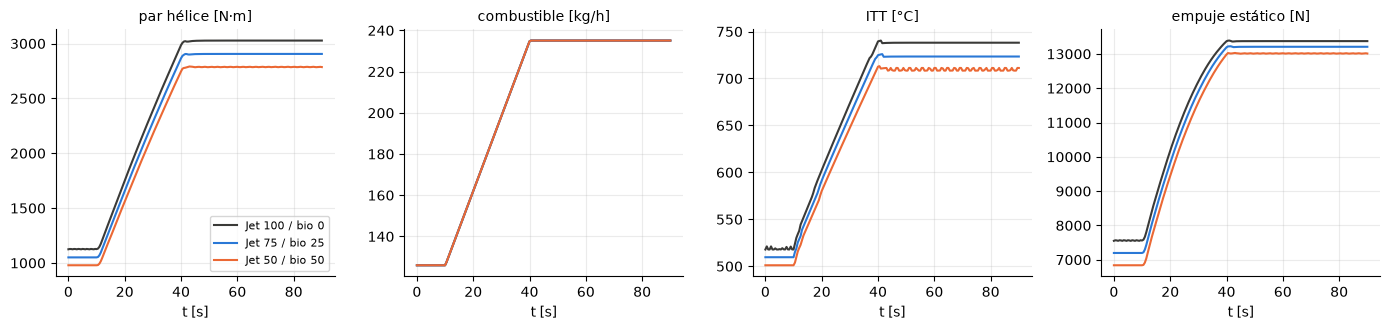

,combustible,par final [N·m],w_f [kg/h],ITT [°C],empuje [N],Ng [%],SFC,Δ par vs Jet [%],Δ w_f vs Jet [%]
0,Jet 100 / bio 0,3027.03,235.05,738.12,13372.39,100.01,0.37,0.00,0.0
1,Jet 75 / bio 25,2905.25,235.05,723.41,13207.23,99.00,0.39,-4.02,0.0
2,Jet 50 / bio 50,2785.39,235.05,711.20,13010.72,98.01,0.40,-7.98,0.0


In [31]:
t0 = time.time()
for x in [1.0, 0.75, 0.5]:
    for lazo in ["abierto", "cerrado"]:
        def _f(x=x, lazo=lazo):
            perfil, cb = ensayo_combustible(x, lazo)
            y0 = y_inicial(0.82*NG100, 2000.0, comb=cb)
            y0 = list(simular(lambda t: perfil(0.0), 30.0, y0=y0, comb=cb, n=11, max_step=0.5)["y_fin"])
            return simular(perfil, 90.0, y0=y0, comb=cb, n=181, max_step=0.2)
        correr("comb_%.2f_%s" % (x, lazo), _f)
print("ensayos de combustible listos (%.0f s)" % (time.time() - t0))
def widget_comb(lazo="cerrado"):
    fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))
    fil = []
    for x, c in [(1.0, COL["tinta"]), (0.75, COL["aire"]), (0.5, COL["pt"])]:
        r = CACHE["comb_%.2f_%s" % (x, lazo)]
        lab = "Jet %.0f / bio %.0f" % (100*x, 100*(1 - x))
        for a, k2 in zip(axs, ["Q", "wf", "ITT", "T"]):
            a.plot(r["t"], r[k2]*(3600 if k2 == "wf" else 1), color=c, label=lab)
        fil.append({"combustible": lab, "par final [N·m]": r["Q"][-1], "w_f [kg/h]": 3600*r["wf"][-1],
                    "ITT [°C]": r["ITT"][-1], "empuje [N]": r["T"][-1], "Ng [%]": r["Ng_pct"][-1], "SFC": r["SFC"][-1]})
    for a, tt in zip(axs, ["par hélice [N·m]", "combustible [kg/h]", "ITT [°C]", "empuje estático [N]"]):
        a.set_title(tt, fontsize=10); a.set_xlabel("t [s]")
    axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
    T = pd.DataFrame(fil); T["Δ par vs Jet [%]"] = 100*(T["par final [N·m]"]/T["par final [N·m]"][0] - 1)
    T["Δ w_f vs Jet [%]"] = 100*(T["w_f [kg/h]"]/T["w_f [kg/h]"][0] - 1)
    display(T.round(2))
w10 = ToggleButtons(options=[("lazo abierto (entrega)", "abierto"), ("lazo cerrado (motor real)", "cerrado")], description="control")
display(VBox([w10, interactive_output(widget_comb, dict(lazo=w10))]))

En lazo abierto el par cae casi en proporción al LHV: es el resultado de la entrega, y es correcto **para ese experimento**. En lazo cerrado el par es el mismo y lo que cambia es el **consumo**, que sube con 1/LHV, y levemente la ITT. La pregunta relevante para un biocombustible de aviación no es "¿cuánta potencia pierdo?", sino **cuánto alcance pierdo** (más kg de combustible por vuelo) y si cumple las propiedades en frío, de lubricidad y de estabilidad que exige la norma (ASTM D7566).

## 13. 🎓 Hallazgos sobre las entregas, verificados en este cuadernillo

In [32]:
hall = pd.DataFrame([
    ("Traub (Simulink 2024)", "C_l divide en los integrandos de T y Q", "singularidad cuando C_l→0: par −4.7×10⁵ N·m a 50 m/s", "§7, réplica literal"),
    ("Traub", "pérdida de punta multiplica por sin β", "F casi constante, sin efecto de punta", "§7"),
    ("Traub", "ajuste de grado 2 integrado como recta con coeficientes cruzados", "T y Q sin sentido físico", "§7"),
    ("Traub", "σ = 1.5 sobre ángulos en radianes", "X ≈ 0.3-0.6 siempre: no hay modelo de pérdida", "§7"),
    ("Hélice", "R = 0.9 m en el código (real 1.193 m); torsión creciente hacia la punta (medida: 58° → 13°); α_0L positivo", "carga radial invertida", "§7, artículo McCauley Fig. 5b"),
    ("Pérdida", "α_stall 2D de XFOIL (4.6-14°) en lugar del efectivo 20.6° del artículo; ajustes de grado 6 divergen (C_l,md = 14 a Re 2×10⁶)", "pala en pérdida prematura (sin retraso rotacional 3D)", "§7"),
    ("Límite de 60 m/s", "atribuido a la física; es la singularidad 1/C_l", "el modelo corregido opera hasta 150 m/s", "§7, W5"),
    ("Compresor (2019/2024)", "anillo de la etapa 3 un 32 % menor que el necesario", "la etapa 3 se estrangula antes del diseño", "§4"),
    ("Misión", "ruta El Dorado-Guaymaral simulada desde 0 m", "a 2548 m el despegue queda limitado por Ng: 2.76 kN·m (91 %)", "§11, W9"),
    ("Ng", "resultados de 45 000-47 000 rpm", "TCDS: máximo 39 000 rpm (104 %)", "TCDS"),
    ("Eficiencia térmica", "40 % reportado", "con sus datos: 2563 N·m × 209 rad/s / (0.06 kg/s × 43.1 MJ/kg) = 21 %; el modelo da 22.5 %", "§10"),
    ("Ecuación 'propulsiva'", "η = 1 − (T4−T1)/(T3−T2) se rotula como propulsiva", "es la eficiencia térmica de Brayton", "manuscrito"),
    ("Biocombustibles", "−18 % de par con 50/50", "artefacto del combustible en lazo abierto (el modelo da −8 %); en lazo cerrado el par se conserva y w_f sube 3.7 % y 6.9 %", "§12, W10"),
    ("LHV de mezclas", "texto: Jet A-1 43.1 MJ/kg; tabla calculada con 43.2", "inconsistencia menor (0.2 %)", "manuscrito")],
    columns=["dónde", "qué", "consecuencia", "verificación"])
display(hall)

,dónde,qué,consecuencia,verificación
0,Traub (Simulink 2024),C_l divide en los integrandos de T y Q,singularidad cuando C_l→0: par −4.7×10⁵ N·m a ...,"§7, réplica literal"
1,Traub,pérdida de punta multiplica por sin β,"F casi constante, sin efecto de punta",§7
2,Traub,ajuste de grado 2 integrado como recta con coe...,T y Q sin sentido físico,§7
3,Traub,σ = 1.5 sobre ángulos en radianes,X ≈ 0.3-0.6 siempre: no hay modelo de pérdida,§7
4,Hélice,R = 0.9 m en el código (real 1.193 m); torsión...,carga radial invertida,"§7, artículo McCauley Fig. 5b"
5,Pérdida,α_stall 2D de XFOIL (4.6-14°) en lugar del efe...,pala en pérdida prematura (sin retraso rotacio...,§7
6,Límite de 60 m/s,atribuido a la física; es la singularidad 1/C_l,el modelo corregido opera hasta 150 m/s,"§7, W5"
7,Compresor (2019/2024),anillo de la etapa 3 un 32 % menor que el nece...,la etapa 3 se estrangula antes del diseño,§4
8,Misión,ruta El Dorado-Guaymaral simulada desde 0 m,a 2548 m el despegue queda limitado por Ng: 2....,"§11, W9"
9,Ng,resultados de 45 000-47 000 rpm,TCDS: máximo 39 000 rpm (104 %),TCDS


## 14. Verificación

Condición de "terminado" del proyecto: un caso de referencia con error < 1 %. Se usan siete comprobaciones internas y de datos:

In [33]:
o = estacionario(NG100, 2000.0)
T0, p0, Ta, pa, rho, mu = admision(0.0, 0.0)
e = termo_motor(NG100, TCDS["Npt"], o["p3"], o["T4"], o["wf"], dict(T0=T0, p0=p0, T=Ta, p=pa, rho=rho, mu=mu), D["comb"])
G = e["G"]
H_in = e["mc"]*(AIRE.hT(T0) + DH_REF) + o["wf"]*D["comb"]["hf"]
H_out = e["m4"]*float(G.hT(e["T6"])) + e["P_ct"] + e["P_pt"] - e["W_c"]
dh_cp = AIRE.hT(D["T3"]) - AIRE.hT(D["T2"])
_g.TPX = D["T3"], ct.one_atm, X_AIRE; h3c = _g.enthalpy_mass; _g.TPX = D["T2"], ct.one_atm, X_AIRE; h2c = _g.enthalpy_mass
mc_map, _, _, _ = mapa_compresor(1.0*math.sqrt(288.15/D["T2"]), D["p3"]/D["p2"])
m_corr = D["m"]*math.sqrt(D["T2"]/288.15)/(D["p2"]/101325)
y0 = y_inicial(0.95*NG100, 2000.0)
rs = simular(lambda t: dict(h=0.0, V=0.0, Ng=NG100, N2=2000.0), 40.0, y0=y0, n=81, max_step=0.2)
ver = pd.DataFrame([
    ("1. Potencia de diseño reproducida por las EDO", o["P"]/1e3, 634.0, 100*(o["P"]/634e3 - 1)),
    ("2. ITT de diseño (carta 738 °C)", o["ITT"], 738.0, 100*(o["ITT"] - 738)/(738 + 273.15)),
    ("3. Primera ley global (entrada vs. ejes + escape) [kW]", H_in/1e3, H_out/1e3, 100*(H_in - H_out)/(o["wf"]*D["comb"]["LHV"])),
    ("4. Masa en la cámara: ṁ_c + w_f vs. ṁ_4 [kg/s]", e["mc"] + o["wf"], e["m4"], 100*(e["mc"] + o["wf"] - e["m4"])/e["m4"]),
    ("5. Δh compresor: CoolProp vs. Cantera [kJ/kg]", dh_cp/1e3, (h3c - h2c)/1e3, 100*(dh_cp/(h3c - h2c) - 1)),
    ("6. Inversión del mapa: ṁ corregido [kg/s]", mc_map, m_corr, 100*(mc_map/m_corr - 1)),
    ("7. Transitorio 95→100 % converge al estacionario [kW]", rs["P"][-1]/1e3, o["P"]/1e3, 100*(rs["P"][-1]/o["P"] - 1))],
    columns=["comprobación", "modelo", "referencia", "error [%]"])
ver["< 1 %"] = ver["error [%]"].abs() < 1.0
display(ver.round(4))
print("LHV Jet-A(g) NASA vs. especificación: %+.2f %% (V4, §5)" % err_lhv)
print("Todas las comprobaciones < 1 %:", bool(ver["< 1 %"].all()))

,comprobación,modelo,referencia,error [%],< 1 %
0,1. Potencia de diseño reproducida por las EDO,633.8842,634.0000,-0.0183,True
1,2. ITT de diseño (carta 738 °C),738.0471,738.0000,0.0047,True
2,3. Primera ley global (entrada vs. ejes + esca...,-166.0206,-166.0202,-0.0000,True
3,4. Masa en la cámara: ṁ_c + w_f vs. ṁ_4 [kg/s],3.5384,3.5384,0.0007,True
4,5. Δh compresor: CoolProp vs. Cantera [kJ/kg],307.4184,307.5539,-0.0441,True
5,6. Inversión del mapa: ṁ corregido [kg/s],3.5080,3.5087,-0.0207,True
6,7. Transitorio 95→100 % converge al estacionar...,633.4335,633.8842,-0.0711,True


LHV Jet-A(g) NASA vs. especificación: +0.58 % (V4, §5)
Todas las comprobaciones < 1 %: True


## Conclusión

El PT6A-61 se entiende como **dos máquinas acopladas por el gas**.

**El generador de gas** es una bomba de aire:
- sus triángulos de velocidad fijan cuánto aire mueve y cuánto trabajo le da;
- la tobera estrangulada de la turbina decide en qué punto del mapa opera.

**La turbina libre y la hélice** forman un freno aerodinámico gobernado. Su par crece con el paso y cae con la velocidad, y el gobernador mueve el paso hasta que las rpm vuelven a la referencia. Ninguno de los dos ejes necesita un rozamiento artificial para tener equilibrio.

**Validación.** El modelo, calibrado con cinco parámetros físicos contra la carta de P&WC y la potencia certificada:
- reproduce el punto de despegue;
- predice la presión entre turbinas (−7 %) y la temperatura de escape (−3 % en K);
- con la geometría medida de la hélice y sin ajustar nada, reproduce el par RANS del artículo McCauley en rodaje, estático y despegue (±6 %); en crucero subestima, como el BEMT del propio artículo;
- predice el límite de potencia plana (36.5 °C contra 46 °C del TCDS).

**Lo que dejan las entregas.** Tienen un valor que este cuadernillo conserva:
- la caracterización de la pala escaneada (XFOIL, geometría y CFD del artículo McCauley);
- la geometría medida del motor;
- la idea de acoplar motor y hélice en un solo modelo.

Sus conclusiones más llamativas, en cambio, vienen de errores de implementación o de supuestos:
- el límite de 60 m/s;
- el 18 % de pérdida con biodiésel;
- el 40 % de eficiencia térmica.

Separar el fenómeno físico del artefacto numérico es la lección metodológica central.

## Ejercicios de extensión
1. **Triángulos de la turbina.** Con los radios de la tesis (TC: 0.092–0.117 m; TP: 0.088–0.142 m), calcula $\nu=U/c_0$ en el punto de diseño y el grado de reacción. ¿Es coherente con $\nu_d$ de §6?
2. **Recalibrar la potencia plana.** Supón que en la carta de P&WC el motor gira al 97 % de $N_g$. Repite `calibrar_compresor()` con esa velocidad y vuelve a predecir la temperatura límite de 634 kW. ¿Se acerca a los 46 °C del TCDS?
3. **BEMT iterativo robusto.** Reescribe la iteración de la Lección 14 con `brentq` sobre el ángulo de flujo $\phi$ (formulación de Ning, 2021). Compárala con Traub y con el CFD del artículo en las condiciones de crucero de V3. ¿Reduce la brecha?
4. **Despegue en Bogotá en día caliente.** Con ΔT = +15 K a 2548 m, ¿cuál limita, ITT o $N_g$? ¿Qué par queda disponible y cuánto se alarga la carrera de despegue si la fuerza neta es proporcional al empuje estático?
5. **SAF parafínico (HEFA, LHV ≈ 44 MJ/kg, C₁₂H₂₆).** Agrégalo a `COMB` y compara el consumo de la misión corregida con Jet A-1.

## Referencias
- Delgado Pinzón, S. V.; González Posada, J. P.; Reyes Perilla, J. J.; Bayona Roa, C. A. (2024). *Simulation of Turboprop Systems using Simulink: Development and Validation of Computational Mechanical Model*. Manuscrito, PUJ.
- Castellanos Proaños, D. A. (2019). *Simulación computacional de operación de turbina de gas tipo PT6*. Tesis, Universidad ECCI.
- Bayona-Roa, C. A. et al. (2019). Computational Simulation of PT6A Gas Turbine Engine Operating with Different Blends of Biodiesel. *Energies* 12(22).
- Castellanos-Proaños, D.; Bayona-Roa, C.; López Gómez, M.; García-Navarro, J. G. *Aerodynamic analysis of a four-bladed McCauley propeller integrating low-order BEM with high-order CFD in a computational simulation framework*. Manuscrito (AIAA).
- Traub, L. W. (2016). Simplified propeller analysis and design including effects of stall. *The Aeronautical Journal* 120(1227).
- Yoshinaka, T.; Thue, K. S. (1985). A Cost-Effective Performance Development of the PT6A-65 Turboprop Compressor. ASME 85-IGT-41.
- EASA (2022). TCDS IM.E.078, Pratt & Whitney Canada PT6A-41 Series Engines, Issue 02.
- Saravanamuttoo, H. I. H. et al. (2017). *Gas Turbine Theory*, 7.ª ed. Pearson.
- Dixon, S. L.; Hall, C. A. (2014). *Fluid Mechanics and Thermodynamics of Turbomachinery*, 7.ª ed.
- Gudmundsson, S. (2021). *General Aviation Aircraft Design*, 2.ª ed. Butterworth-Heinemann.